<a href="https://colab.research.google.com/github/Aletz44/Actividad-5_ABG/blob/main/fuentes/entrena.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Actividad 5. Gestión de Proyectos de Inteligencia Artificial

from IPython.display import display, Markdown

texto_introduccion = r"""
# Actividad 5. Gestión de Proyectos de Inteligencia Artificial

## Predicción de partículas PM2.5 en la Ciudad de México

En esta actividad desarrollaré un proyecto de aprendizaje automático utilizando información pública de la Red Automática de Monitoreo Atmosférico (RAMA) de la Ciudad de México.

El problema que abordaré consiste en estimar la concentración de partículas PM2.5 del día siguiente, tomando como referencia los registros históricos de contaminación atmosférica.

Para desarrollar el proyecto, realizaré la preparación y limpieza de los datos, el entrenamiento y la comparación de dos modelos de regresión, así como el ajuste de sus hiperparámetros mediante validación cruzada.

También utilizaré MLflow para registrar los parámetros, las métricas y los resultados de los experimentos, con el propósito de facilitar su comparación y reproducibilidad.

Finalmente, analizaré el desempeño de los modelos, identificaré sus principales limitaciones y justificaré la selección del modelo que presente los resultados más adecuados para el problema planteado.
"""

display(Markdown(texto_introduccion))


# Actividad 5. Gestión de Proyectos de Inteligencia Artificial

## Predicción de partículas PM2.5 en la Ciudad de México

En esta actividad desarrollaré un proyecto de aprendizaje automático utilizando información pública de la Red Automática de Monitoreo Atmosférico (RAMA) de la Ciudad de México.

El problema que abordaré consiste en estimar la concentración de partículas PM2.5 del día siguiente, tomando como referencia los registros históricos de contaminación atmosférica.

Para desarrollar el proyecto, realizaré la preparación y limpieza de los datos, el entrenamiento y la comparación de dos modelos de regresión, así como el ajuste de sus hiperparámetros mediante validación cruzada.

También utilizaré MLflow para registrar los parámetros, las métricas y los resultados de los experimentos, con el propósito de facilitar su comparación y reproducibilidad.

Finalmente, analizaré el desempeño de los modelos, identificaré sus principales limitaciones y justificaré la selección del modelo que presente los resultados más adecuados para el problema planteado.


In [2]:
# TAREA 5
# Actividad 1. Preparación del entorno y repositorio

from IPython.display import display, Markdown

# Instalación de dependencias
import sys
import subprocess

print("=" * 65)
print("1. INSTALACIÓN DE DEPENDENCIAS")
print("=" * 65)

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "mlflow"],
    check=True
)

print("Instalación de MLflow completada.")

# Importación de bibliotecas
print("\n" + "=" * 65)
print("2. IMPORTACIÓN DE BIBLIOTECAS")
print("=" * 65)

import os
import random
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import mlflow

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Todas las bibliotecas se importaron correctamente.")

# Configuración de Reproducibilidad
print("\n" + "=" * 65)
print("3. CONFIGURACIÓN DE REPRODUCIBILIDAD")
print("=" * 65)

SEMILLA = 42

random.seed(SEMILLA)
np.random.seed(SEMILLA)

print(f"Semilla aleatoria establecida: {SEMILLA}")

# Verificación de versiones
print("\n" + "=" * 65)
print("4. VERSIONES DEL ENTORNO")
print("=" * 65)

versiones = {
    "Python": platform.python_version(),
    "Pandas": pd.__version__,
    "NumPy": np.__version__,
    "Matplotlib": matplotlib.__version__,
    "Seaborn": sns.__version__,
    "Scikit-learn": sklearn.__version__,
    "MLflow": mlflow.__version__
}

df_versiones = pd.DataFrame(
    list(versiones.items()),
    columns=["Herramienta", "Versión"]
)

display(df_versiones)

print("\nConfiguración inicial del entorno completada.")


1. INSTALACIÓN DE DEPENDENCIAS
Instalación de MLflow completada.

2. IMPORTACIÓN DE BIBLIOTECAS
Todas las bibliotecas se importaron correctamente.

3. CONFIGURACIÓN DE REPRODUCIBILIDAD
Semilla aleatoria establecida: 42

4. VERSIONES DEL ENTORNO


,Herramienta,Versión
0,Python,3.13.16
1,Pandas,2.2.3
2,NumPy,2.1.3
3,Matplotlib,3.10.0
4,Seaborn,0.13.2
5,Scikit-learn,1.6.1
6,MLflow,3.17.1



Configuración inicial del entorno completada.


In [3]:
# TAREA 5
# Actividad 1. Preparación y gestión de datos
# Carga y verificación del DataSet RAMA

# Configuración de la fuente de datos
print("=" * 65)
print("1. CONFIGURACIÓN DE LA FUENTE DE DATOS")
print("=" * 65)

import pandas as pd
from urllib.parse import quote

usuario_github = "Aletz44"
repositorio = "Actividad-5_ABG"
rama = "main"

archivo_csv = "ebc079e5-bd11-4830-b595-14292f753575.csv"

ruta_archivo = f"datos/{archivo_csv}"

url_csv = (
    f"https://raw.githubusercontent.com/"
    f"{usuario_github}/{repositorio}/{rama}/"
    f"{quote(ruta_archivo, safe='/')}"
)

print("Repositorio:", repositorio)
print("Archivo original:", archivo_csv)
print("Ruta:", ruta_archivo)

# Carga del dataset original
print("\n" + "=" * 65)
print("2. CARGA DEL DATASET ORIGINAL")
print("=" * 65)

try:
    df_original = pd.read_csv(url_csv)

    print("Dataset cargado correctamente desde GitHub.")

except Exception as error:
    print("No fue posible cargar el archivo.")
    print("Detalle del error:", error)
    raise

# Dimensiones del dataset
print("\n" + "=" * 65)
print("3. DIMENSIONES DEL DATASET")
print("=" * 65)

filas, columnas = df_original.shape

print(f"Total de registros: {filas:,}")
print(f"Total de columnas: {columnas}")

# Visualización de los primeros registros
print("\n" + "=" * 65)
print("4. PRIMEROS CINCO REGISTROS")
print("=" * 65)

display(df_original.head())

# Identificación de variables y tipos de datos
print("\n" + "=" * 65)
print("5. VARIABLES Y TIPOS DE DATOS")
print("=" * 65)

tabla_variables = pd.DataFrame({
    "Variable": df_original.columns,
    "Tipo de dato": df_original.dtypes.astype(str).values,
    "Valores no nulos": df_original.notna().sum().values
})

display(tabla_variables)

# Revisión del periodo de mediciones
print("\n" + "=" * 65)
print("6. PERIODO DE MEDICIONES")
print("=" * 65)

if "fecha" in df_original.columns:

    # Convertir las fechas utilizando el formato del archivo:
    # YYYY-MM-DD (año-mes-día).

    fechas = pd.to_datetime(
        df_original["fecha"],
        format="%Y-%m-%d",
        errors="coerce"
    )

    print("Fecha inicial:", fechas.min())
    print("Fecha final:", fechas.max())
    print("Fechas no interpretadas:", fechas.isna().sum())

    # Comprobar si existen fechas duplicadas.
    print("Fechas duplicadas:", fechas.duplicated().sum())

    # Verificar la continuidad de los registros diarios.
    if fechas.notna().all():

        fechas_esperadas = pd.date_range(
            start=fechas.min(),
            end=fechas.max(),
            freq="D"
        )

        fechas_faltantes = fechas_esperadas.difference(fechas)

        print("Días sin registro:", len(fechas_faltantes))

else:
    print("No se encontró la columna 'fecha'.")

# Confirmación de la revisión inicial
print("\n" + "=" * 65)
print("7. RESULTADO DE LA REVISIÓN")
print("=" * 65)

print("La carga y revisión estructural del dataset ha finalizado.")
print("Los datos originales permanecen sin modificaciones.")


1. CONFIGURACIÓN DE LA FUENTE DE DATOS
Repositorio: Actividad-5_ABG
Archivo original: ebc079e5-bd11-4830-b595-14292f753575.csv
Ruta: datos/ebc079e5-bd11-4830-b595-14292f753575.csv

2. CARGA DEL DATASET ORIGINAL
Dataset cargado correctamente desde GitHub.

3. DIMENSIONES DEL DATASET
Total de registros: 3,073
Total de columnas: 9

4. PRIMEROS CINCO REGISTROS


,fecha,CO,NO,NO2,NOX,O3,PM10,PM25,SO2
0,2015-01-01,1.050696,22.765528,24.225155,46.987578,23.175150,105.573684,78.953405,11.554723
1,2015-01-02,0.807585,32.249608,21.554160,53.800628,17.268366,36.687845,15.449438,1.895052
2,2015-01-03,0.640755,21.686916,19.394081,41.071651,15.486486,29.269022,12.915129,1.436937
3,2015-01-04,0.726940,24.606272,19.560976,44.165505,17.329032,39.961538,16.838284,1.809061
4,2015-01-05,0.530815,11.443182,20.990260,32.439935,14.470588,31.855643,12.667774,8.315789



5. VARIABLES Y TIPOS DE DATOS


,Variable,Tipo de dato,Valores no nulos
0,fecha,object,3073
1,CO,float64,3073
2,NO,float64,3073
3,NO2,float64,3073
4,NOX,float64,3073
5,O3,float64,3073
6,PM10,float64,3073
7,PM25,float64,3073
8,SO2,float64,3073



6. PERIODO DE MEDICIONES
Fecha inicial: 2015-01-01 00:00:00
Fecha final: 2023-05-31 00:00:00
Fechas no interpretadas: 0
Fechas duplicadas: 0
Días sin registro: 0

7. RESULTADO DE LA REVISIÓN
La carga y revisión estructural del dataset ha finalizado.
Los datos originales permanecen sin modificaciones.


1. PREPARACIÓN DEL DIAGNÓSTICO
Registros analizados: 3073
Variables numéricas: 8
Variable objetivo: PM25

2. VALORES FALTANTES POR VARIABLE


,Variable,Valores faltantes,Porcentaje (%)
0,fecha,0,0.0
1,CO,0,0.0
2,NO,0,0.0
3,NO2,0,0.0
4,NOX,0,0.0
5,O3,0,0.0
6,PM10,0,0.0
7,PM25,0,0.0
8,SO2,0,0.0


Total de valores faltantes: 0

3. REGISTROS DUPLICADOS
Registros completamente duplicados: 0
Fechas duplicadas: 0

4. ESTADÍSTICAS DESCRIPTIVAS


,Registros,Promedio,Desviación estándar,Mínimo,Percentil 25,Mediana,Percentil 75,Máximo
CO,3073.0,0.482,0.205,0.116,0.327,0.444,0.597,1.832
NO,3073.0,14.712,8.858,1.168,8.019,12.670,19.386,75.807
NO2,3073.0,23.030,6.755,8.062,18.188,22.422,26.854,72.193
NOX,3073.0,37.997,14.796,9.983,26.938,35.880,46.740,148.006
O3,3073.0,30.486,9.023,3.226,23.923,29.838,36.216,67.444
PM10,3073.0,41.893,16.047,8.218,29.484,40.041,52.709,115.334
PM25,3073.0,21.327,8.796,2.849,15.345,20.550,26.213,86.910
SO2,3073.0,3.690,3.490,0.630,1.557,2.484,4.377,31.462



5. REVISIÓN DE VALORES NEGATIVOS Y CEROS


,Variable,Valores negativos,Valores iguales a cero
0,CO,0,0
1,NO,0,0
2,NO2,0,0
3,NOX,0,0
4,O3,0,0
5,PM10,0,0
6,PM25,0,0
7,SO2,0,0



6. DETECCIÓN DE POSIBLES VALORES ATÍPICOS (IQR)


,Variable,Límite inferior,Límite superior,Posibles atípicos,Porcentaje (%)
0,CO,-0.077,1.002,55,1.79
1,NO,-9.032,36.437,74,2.41
2,NO2,5.190,39.853,59,1.92
3,NOX,-2.764,76.442,50,1.63
4,O3,5.484,54.655,23,0.75
5,PM10,-5.353,87.546,20,0.65
6,PM25,-0.958,42.515,51,1.66
7,SO2,-2.673,8.607,255,8.30



7. DISTRIBUCIÓN DE LAS CONCENTRACIONES DE PM2.5


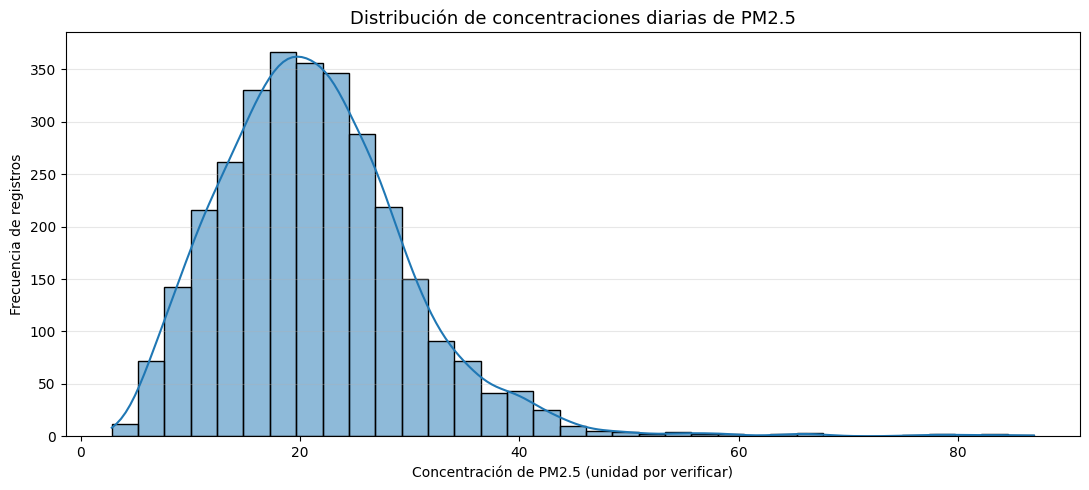


8. RESUMEN DEL DIAGNÓSTICO DE CALIDAD
Registros originales: 3073
Valores faltantes: 0
Registros duplicados: 0
Valores negativos detectados: 0
Posibles valores atípicos: 587

Diagnóstico finalizado.
No se han eliminado ni modificado mediciones originales.


In [4]:
# TAREA 5
# Actividad 1. Preparación y gestión de datos
# Diagnóstico de calidad del dataset RAMA

# Creación de una copia para el análisis
print("=" * 65)
print("1. PREPARACIÓN DEL DIAGNÓSTICO")
print("=" * 65)

# Se conserva df_original sin modificaciones.
df_diagnostico = df_original.copy()

# Conversión de la fecha al formato identificado en la Celda 3.
df_diagnostico["fecha"] = pd.to_datetime(
    df_diagnostico["fecha"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Identificación de las variables de contaminantes.
columnas_numericas = df_diagnostico.select_dtypes(
    include=["number"]
).columns.tolist()

print("Registros analizados:", len(df_diagnostico))
print("Variables numéricas:", len(columnas_numericas))
print("Variable objetivo: PM25")

# Identificación de valores faltantes
print("\n" + "=" * 65)
print("2. VALORES FALTANTES POR VARIABLE")
print("=" * 65)

tabla_nulos = pd.DataFrame({
    "Variable": df_diagnostico.columns,
    "Valores faltantes": df_diagnostico.isna().sum().values,
    "Porcentaje (%)": (
        df_diagnostico.isna().mean().values * 100
    ).round(2)
})

display(tabla_nulos)

print(
    "Total de valores faltantes:",
    int(df_diagnostico.isna().sum().sum())
)

# Identificación de registros duplicados
print("\n" + "=" * 65)
print("3. REGISTROS DUPLICADOS")
print("=" * 65)

duplicados_completos = df_diagnostico.duplicated().sum()

duplicados_fecha = df_diagnostico.duplicated(
    subset=["fecha"]
).sum()

print("Registros completamente duplicados:", duplicados_completos)
print("Fechas duplicadas:", duplicados_fecha)

# Estadísticas descriptivas
print("\n" + "=" * 65)
print("4. ESTADÍSTICAS DESCRIPTIVAS")
print("=" * 65)

estadisticas = df_diagnostico[
    columnas_numericas
].describe().T

estadisticas = estadisticas.rename(columns={
    "count": "Registros",
    "mean": "Promedio",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "Percentil 25",
    "50%": "Mediana",
    "75%": "Percentil 75",
    "max": "Máximo"
})

display(estadisticas.round(3))

# Valores negativos y valores iguales a cero
# Los valores negativos requieren revisión porque las
# concentraciones físicas no deberían ser negativas.
# Los ceros se analizan, pero no se eliminan automáticamente.
print("\n" + "=" * 65)
print("5. REVISIÓN DE VALORES NEGATIVOS Y CEROS")
print("=" * 65)

tabla_valores = pd.DataFrame({
    "Variable": columnas_numericas,
    "Valores negativos": [
        int((df_diagnostico[col] < 0).sum())
        for col in columnas_numericas
    ],
    "Valores iguales a cero": [
        int((df_diagnostico[col] == 0).sum())
        for col in columnas_numericas
    ]
})

display(tabla_valores)

# Identificación de posibles valores atípicos
print("\n" + "=" * 65)
print("6. DETECCIÓN DE POSIBLES VALORES ATÍPICOS (IQR)")
print("=" * 65)

resultados_atipicos = []

for columna in columnas_numericas:

    q1 = df_diagnostico[columna].quantile(0.25)
    q3 = df_diagnostico[columna].quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = (
        (df_diagnostico[columna] < limite_inferior) |
        (df_diagnostico[columna] > limite_superior)
    )

    resultados_atipicos.append({
        "Variable": columna,
        "Límite inferior": round(limite_inferior, 3),
        "Límite superior": round(limite_superior, 3),
        "Posibles atípicos": int(atipicos.sum()),
        "Porcentaje (%)": round(
            atipicos.mean() * 100, 2
        )
    })

tabla_atipicos = pd.DataFrame(resultados_atipicos)

display(tabla_atipicos)

# Visualización de la distribución de PM2.5
print("\n" + "=" * 65)
print("7. DISTRIBUCIÓN DE LAS CONCENTRACIONES DE PM2.5")
print("=" * 65)

plt.figure(figsize=(11, 5))

sns.histplot(
    data=df_diagnostico,
    x="PM25",
    bins=35,
    kde=True
)

plt.title(
    "Distribución de concentraciones diarias de PM2.5",
    fontsize=13
)

plt.xlabel("Concentración de PM2.5 (unidad por verificar)")
plt.ylabel("Frecuencia de registros")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Resumen del diagnóstico
print("\n" + "=" * 65)
print("8. RESUMEN DEL DIAGNÓSTICO DE CALIDAD")
print("=" * 65)

print("Registros originales:", len(df_original))

print(
    "Valores faltantes:",
    int(df_diagnostico.isna().sum().sum())
)

print(
    "Registros duplicados:",
    int(duplicados_completos)
)

print(
    "Valores negativos detectados:",
    int(tabla_valores["Valores negativos"].sum())
)

print(
    "Posibles valores atípicos:",
    int(tabla_atipicos["Posibles atípicos"].sum())
)

print("\nDiagnóstico finalizado.")
print("No se han eliminado ni modificado mediciones originales.")

1. PREPARACIÓN DEL ANÁLISIS TEMPORAL
Registros analizados: 3073
Fecha inicial: 2015-01-01
Fecha final: 2023-05-31

2. EVOLUCIÓN DIARIA DE PM2.5




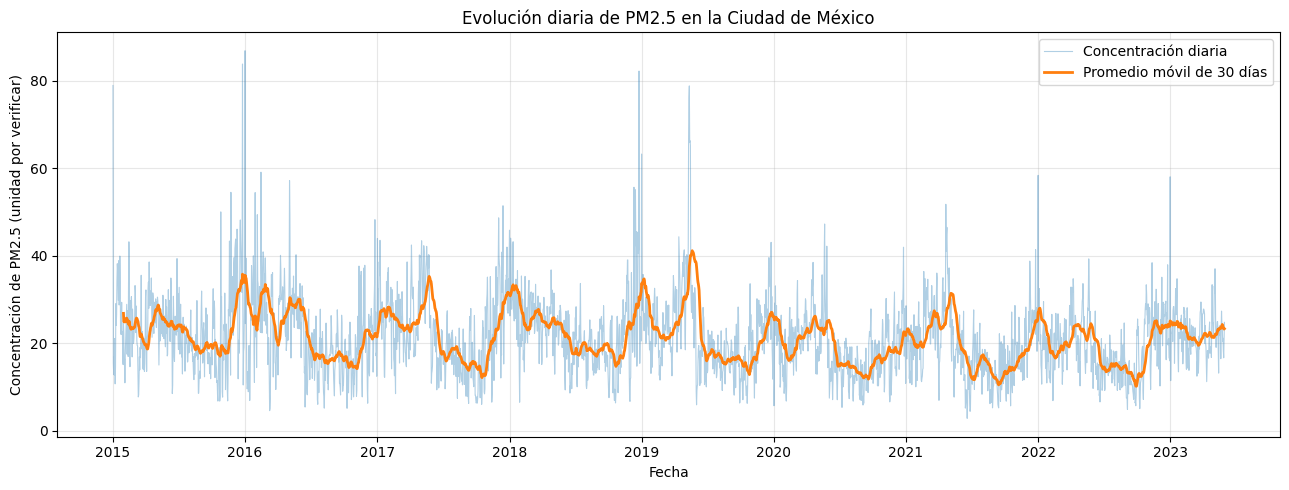


3. PROMEDIOS ANUALES DE PM2.5


,anio,Promedio_PM25,Mediana_PM25,Maximo_PM25,Dias_registrados,Variacion_anual_pct
0,2015,23.57,22.63,83.87,365,NaN
1,2016,22.03,21.23,86.91,366,-6.55
2,2017,22.73,21.94,51.46,365,3.18
3,2018,22.78,22.54,82.26,365,0.22
4,2019,22.21,20.48,78.86,365,-2.51
5,2020,18.67,18.51,47.28,366,-15.92
6,2021,19.24,18.61,51.80,365,3.05
7,2022,18.97,18.43,58.41,365,-1.44
8,2023,22.32,22.20,58.08,151,17.69


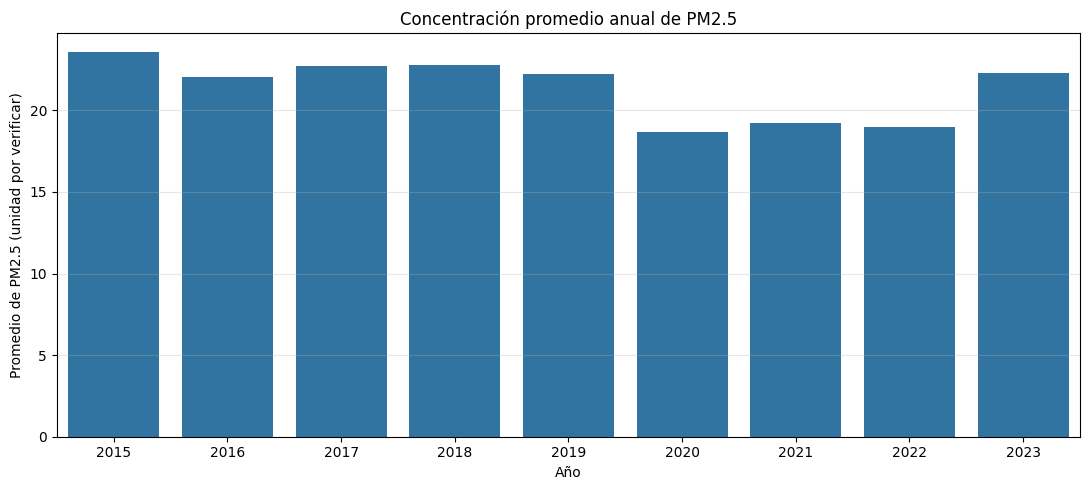


Nota: 2023 contiene únicamente registros hasta mayo.
Su promedio no representa un año calendario completo.

4. COMPORTAMIENTO MENSUAL DE PM2.5


,Mes,Promedio_PM25,Mediana_PM25,Registros
0,1,24.50,23.50,279
1,2,22.99,22.62,254
2,3,22.51,22.46,279
3,4,26.30,25.98,270
4,5,26.66,24.88,279
5,6,17.14,16.38,240
6,7,17.62,17.62,248
7,8,15.39,15.32,248
8,9,15.67,15.29,240
9,10,16.24,15.43,248


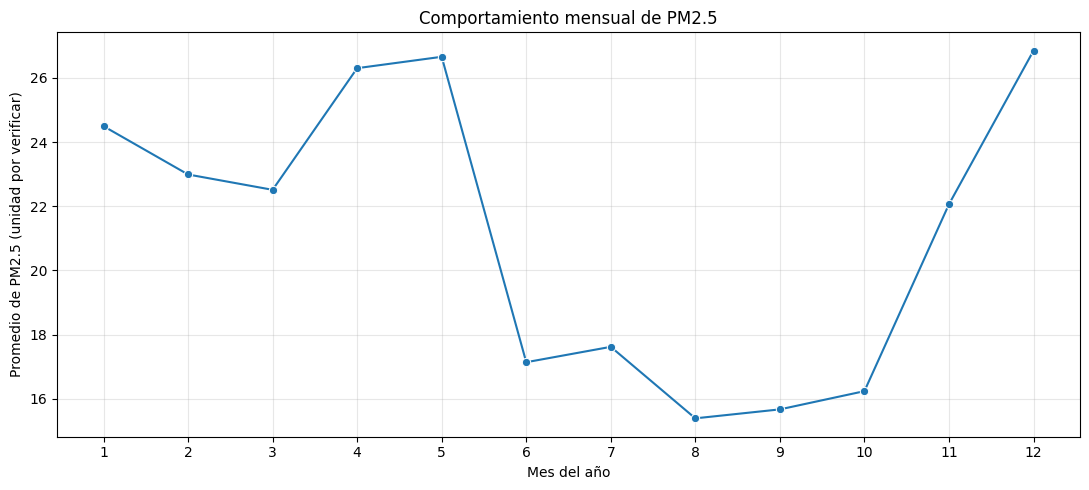


5. DIEZ DÍAS CON MAYOR CONCENTRACIÓN DE PM2.5


,fecha,PM25
0,2016-01-01,86.909910
1,2015-12-25,83.867209
2,2018-12-25,82.258333
3,2015-01-01,78.953405
4,2019-05-13,78.859788
5,2019-05-12,76.172932
6,2019-05-11,67.376316
7,2019-05-15,66.323450
8,2019-05-14,65.990172
9,2019-05-16,65.262873



6. DISTRIBUCIÓN ANUAL DE PM2.5




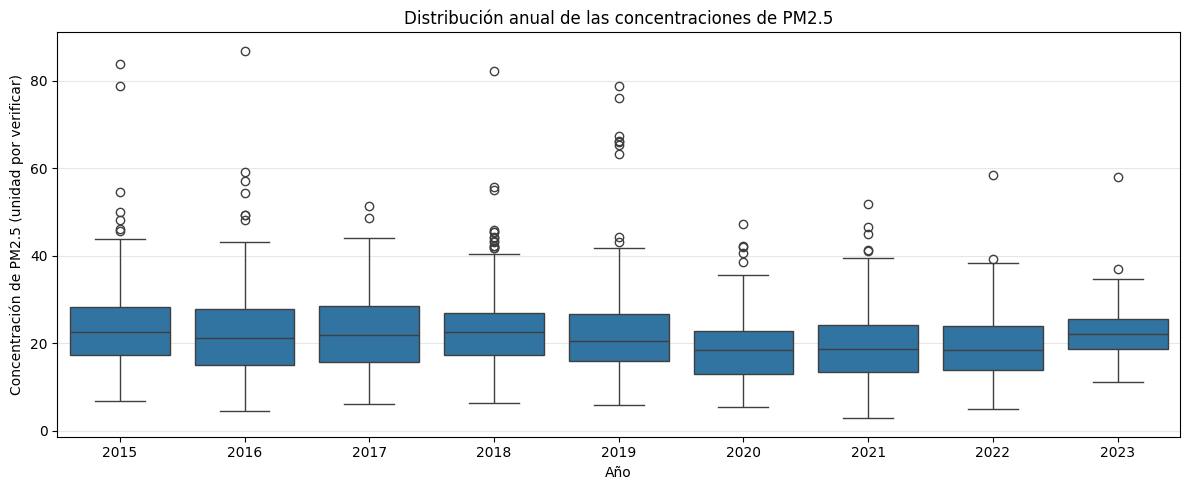


7. RESUMEN DEL ANÁLISIS TEMPORAL
Total de registros: 3073
Año con mayor promedio: 2015
Mes con mayor promedio: 12
Concentración máxima registrada: 86.91

Análisis temporal finalizado.
Los datos originales permanecen sin modificaciones.


In [8]:

# TAREA 5
# Actividad 1. Preparación y gestión de datos
# Análisis temporal de las concentraciones de PM2.5

# Preparación de los datos temporales
print("=" * 65)
print("1. PREPARACIÓN DEL ANÁLISIS TEMPORAL")
print("=" * 65)

# Se utiliza una copia para conservar los datos originales.
df_temporal = df_diagnostico.copy()

# Se ordenan los registros cronológicamente.
df_temporal = df_temporal.sort_values(
    by="fecha"
).reset_index(drop=True)

# Crear variables auxiliares para el análisis temporal.
df_temporal["anio"] = df_temporal["fecha"].dt.year
df_temporal["mes"] = df_temporal["fecha"].dt.month

print("Registros analizados:", len(df_temporal))
print("Fecha inicial:", df_temporal["fecha"].min().date())
print("Fecha final:", df_temporal["fecha"].max().date())

# Evolución diaria de PM2.5
print("\n" + "=" * 65)
print("2. EVOLUCIÓN DIARIA DE PM2.5")
print("=" * 65)

# Cálculo de un promedio móvil de 30 días para facilitar
# la identificación de cambios en el comportamiento general.
df_temporal["PM25_media_30d"] = (
    df_temporal["PM25"]
    .rolling(window=30, min_periods=30)
    .mean()
)

plt.figure(figsize=(13, 5))

plt.plot(
    df_temporal["fecha"],
    df_temporal["PM25"],
    alpha=0.35,
    linewidth=0.8,
    label="Concentración diaria"
)

plt.plot(
    df_temporal["fecha"],
    df_temporal["PM25_media_30d"],
    linewidth=2,
    label="Promedio móvil de 30 días"
)

plt.title("Evolución diaria de PM2.5 en la Ciudad de México")
plt.xlabel("Fecha")
plt.ylabel("Concentración de PM2.5 (unidad por verificar)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
print("\n")
plt.show()

# Promedios anuales de PM2.5
print("\n" + "=" * 65)
print("3. PROMEDIOS ANUALES DE PM2.5")
print("=" * 65)

promedios_anuales = (
    df_temporal.groupby("anio")
    .agg(
        Promedio_PM25=("PM25", "mean"),
        Mediana_PM25=("PM25", "median"),
        Maximo_PM25=("PM25", "max"),
        Dias_registrados=("PM25", "count")
    )
    .reset_index()
)

# Variación porcentual respecto al año anterior.
promedios_anuales["Variacion_anual_pct"] = (
    promedios_anuales["Promedio_PM25"]
    .pct_change() * 100
)

display(promedios_anuales.round(2))

plt.figure(figsize=(11, 5))

sns.barplot(
    data=promedios_anuales,
    x="anio",
    y="Promedio_PM25"
)

plt.title("Concentración promedio anual de PM2.5")
plt.xlabel("Año")
plt.ylabel("Promedio de PM2.5 (unidad por verificar)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
print("\n")
plt.show()

print(
    "\nNota: 2023 contiene únicamente registros hasta mayo."
)
print(
    "Su promedio no representa un año calendario completo."
)

# Comportamiento mensual de PM2.5
print("\n" + "=" * 65)
print("4. COMPORTAMIENTO MENSUAL DE PM2.5")
print("=" * 65)

# Agrupar por mes del calendario para explorar
# posibles patrones estacionales.
promedios_mensuales = (
    df_temporal.groupby("mes")["PM25"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

promedios_mensuales.columns = [
    "Mes",
    "Promedio_PM25",
    "Mediana_PM25",
    "Registros"
]

display(promedios_mensuales.round(2))

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=promedios_mensuales,
    x="Mes",
    y="Promedio_PM25",
    marker="o"
)

plt.title("Comportamiento mensual de PM2.5")
plt.xlabel("Mes del año")
plt.ylabel("Promedio de PM2.5 (unidad por verificar)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
print("\n")
plt.show()

# Días con mayor concentración de PM2.5
print("\n" + "=" * 65)
print("5. DIEZ DÍAS CON MAYOR CONCENTRACIÓN DE PM2.5")
print("=" * 65)

dias_mayor_contaminacion = (
    df_temporal[["fecha", "PM25"]]
    .nlargest(10, "PM25")
    .copy()
)

dias_mayor_contaminacion["fecha"] = (
    dias_mayor_contaminacion["fecha"]
    .dt.strftime("%Y-%m-%d")
)

display(dias_mayor_contaminacion.reset_index(drop=True))

# Distribución anual de PM2.5
print("\n" + "=" * 65)
print("6. DISTRIBUCIÓN ANUAL DE PM2.5")
print("=" * 65)

# Los diagramas de caja permiten comparar medianas,
# dispersión y observaciones potencialmente atípicas.

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df_temporal,
    x="anio",
    y="PM25"
)

plt.title("Distribución anual de las concentraciones de PM2.5")
plt.xlabel("Año")
plt.ylabel("Concentración de PM2.5 (unidad por verificar)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
print("\n")
plt.show()

# Resumen del análisis temporal
print("\n" + "=" * 65)
print("7. RESUMEN DEL ANÁLISIS TEMPORAL")
print("=" * 65)

anio_mayor_promedio = promedios_anuales.loc[
    promedios_anuales["Promedio_PM25"].idxmax(),
    "anio"
]

mes_mayor_promedio = promedios_mensuales.loc[
    promedios_mensuales["Promedio_PM25"].idxmax(),
    "Mes"
]

print("Total de registros:", len(df_temporal))
print("Año con mayor promedio:", anio_mayor_promedio)
print("Mes con mayor promedio:", mes_mayor_promedio)

print(
    "Concentración máxima registrada:",
    round(df_temporal["PM25"].max(), 3)
)

print("\nAnálisis temporal finalizado.")
print("Los datos originales permanecen sin modificaciones.")

In [9]:

# TAREA 5
# Actividad 1. Preparación y gestión de datos
# Ingeniería de características y preparación del conjunto de datos

# Preparación del conjunto de trabajo
print("=" * 65)
print("1. PREPARACIÓN DEL CONJUNTO DE TRABAJO")
print("=" * 65)

# Crear una copia independiente del dataset original.
# Los registros originales permanecerán sin modificaciones.
df_modelo = df_diagnostico.copy()

# Ordenar cronológicamente los registros.
df_modelo = df_modelo.sort_values(
    by="fecha"
).reset_index(drop=True)

# Verificar que las fechas sean únicas y consecutivas.
assert df_modelo["fecha"].notna().all(), \
    "Existen fechas no interpretadas."

assert not df_modelo["fecha"].duplicated().any(), \
    "Existen fechas duplicadas."

assert df_modelo["fecha"].diff().dropna().eq(
    pd.Timedelta(days=1)
).all(), "Existen interrupciones en la serie diaria."

print("Registros originales:", len(df_modelo))
print("Periodo inicial:", df_modelo["fecha"].min().date())
print("Periodo final:", df_modelo["fecha"].max().date())

# Creación de la variable objetivo
print("\n" + "=" * 65)
print("2. CREACIÓN DE LA VARIABLE OBJETIVO")
print("=" * 65)

# El objetivo es predecir PM2.5 del día siguiente.
# shift(-1) desplaza la concentración un día hacia adelante.
df_modelo["PM25_siguiente_dia"] = (
    df_modelo["PM25"].shift(-1)
)

print("Variable objetivo creada: PM25_siguiente_dia")

# Mostrar ejemplos de la relación entre el día actual
# y la concentración que queremos predecir.
display(
    df_modelo[
        ["fecha", "PM25", "PM25_siguiente_dia"]
    ].head(5)
)

# Creación de variables históricas
print("\n" + "=" * 65)
print("3. CREACIÓN DE VARIABLES HISTÓRICAS")
print("=" * 65)

# Las variables rezagadas representan concentraciones
# observadas en días anteriores al día de predicción.
for dias in [1, 2, 3, 7]:

    df_modelo[f"PM25_rezago_{dias}d"] = (
        df_modelo["PM25"].shift(dias)
    )

# Promedios históricos calculados hasta el día actual.
# No incluyen concentraciones del día siguiente.
df_modelo["PM25_media_7d"] = (
    df_modelo["PM25"]
    .rolling(window=7, min_periods=7)
    .mean()
)

df_modelo["PM25_media_30d"] = (
    df_modelo["PM25"]
    .rolling(window=30, min_periods=30)
    .mean()
)

print("Variables históricas creadas:")
print("- Rezagos de 1, 2, 3 y 7 días.")
print("- Promedio móvil de 7 días.")
print("- Promedio móvil de 30 días.")

# Creación de variables temporales
print("\n" + "=" * 65)
print("4. CREACIÓN DE VARIABLES TEMPORALES")
print("=" * 65)

# Utilizar la fecha del día que queremos predecir.
# Esa fecha se conoce anticipadamente.
fecha_prediccion = (
    df_modelo["fecha"] + pd.Timedelta(days=1)
)

df_modelo["mes_prediccion"] = fecha_prediccion.dt.month
df_modelo["dia_semana_prediccion"] = fecha_prediccion.dt.dayofweek

# Representación cíclica del mes.
# Permite reconocer que diciembre y enero son cercanos.
df_modelo["mes_seno"] = np.sin(
    2 * np.pi * df_modelo["mes_prediccion"] / 12
)

df_modelo["mes_coseno"] = np.cos(
    2 * np.pi * df_modelo["mes_prediccion"] / 12
)

print("Variables temporales creadas correctamente.")

# Selección de variables predictorias
print("\n" + "=" * 65)
print("5. SELECCIÓN DE VARIABLES PREDICTORAS")
print("=" * 65)

# Las concentraciones de contaminantes corresponden
# al día actual y no al día siguiente.
variables_predictoras = [
    "CO",
    "NO",
    "NO2",
    "NOX",
    "O3",
    "PM10",
    "PM25",
    "SO2",
    "PM25_rezago_1d",
    "PM25_rezago_2d",
    "PM25_rezago_3d",
    "PM25_rezago_7d",
    "PM25_media_7d",
    "PM25_media_30d",
    "mes_seno",
    "mes_coseno",
    "dia_semana_prediccion"
]

variable_objetivo = "PM25_siguiente_dia"

print("Total de variables predictoras:", len(variables_predictoras))
print("Variable objetivo:", variable_objetivo)

# Tratamiento de registros incompletos
print("\n" + "=" * 65)
print("6. PREPARACIÓN DEL DATASET PARA MODELADO")
print("=" * 65)

# Los primeros días no tienen suficiente historial para
# calcular todas las variables rezagadas y móviles.
# El último día no tiene un valor objetivo posterior.

registros_antes = len(df_modelo)

columnas_requeridas = (
    variables_predictoras + [variable_objetivo]
)

df_modelo_limpio = (
    df_modelo.dropna(subset=columnas_requeridas)
    .copy()
    .reset_index(drop=True)
)

registros_despues = len(df_modelo_limpio)

print("Registros antes:", registros_antes)
print("Registros después:", registros_despues)
print("Registros excluidos:", registros_antes - registros_despues)

print(
    "Valores faltantes restantes:",
    int(df_modelo_limpio[columnas_requeridas].isna().sum().sum())
)

# División cronológica entrenamiento / prueba
print("\n" + "=" * 65)
print("7. DIVISIÓN CRONOLÓGICA DE LOS DATOS")
print("=" * 65)

# Se reserva el 20% final para la evaluación.
# No se mezclan aleatoriamente los registros.

proporcion_entrenamiento = 0.80

punto_corte = int(
    len(df_modelo_limpio) * proporcion_entrenamiento
)

df_entrenamiento = df_modelo_limpio.iloc[
    :punto_corte
].copy()

df_prueba = df_modelo_limpio.iloc[
    punto_corte:
].copy()

X_train = df_entrenamiento[variables_predictoras].copy()
y_train = df_entrenamiento[variable_objetivo].copy()

X_test = df_prueba[variables_predictoras].copy()
y_test = df_prueba[variable_objetivo].copy()

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

print(
    "Periodo entrenamiento:",
    df_entrenamiento["fecha"].min().date(),
    "a",
    df_entrenamiento["fecha"].max().date()
)

print(
    "Periodo prueba:",
    df_prueba["fecha"].min().date(),
    "a",
    df_prueba["fecha"].max().date()
)

# Verificación final
print("\n" + "=" * 65)
print("8. VERIFICACIÓN FINAL DEL DATASET")
print("=" * 65)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

assert (
    df_entrenamiento["fecha"].max()
    <
    df_prueba["fecha"].min()
), "La división cronológica no es correcta."

print("Dimensiones X_train:", X_train.shape)
print("Dimensiones X_test:", X_test.shape)

print("\nPrimeros registros del dataset preparado:")

display(
    df_modelo_limpio[
        ["fecha", "PM25", "PM25_media_7d",
         "PM25_media_30d", "PM25_siguiente_dia"]
    ].head()
)

print("\nPreparación inicial completada correctamente.")
print("Los datos originales permanecen sin modificaciones.")
print("No se ha aplicado estandarización ni entrenamiento.")

1. PREPARACIÓN DEL CONJUNTO DE TRABAJO
Registros originales: 3073
Periodo inicial: 2015-01-01
Periodo final: 2023-05-31

2. CREACIÓN DE LA VARIABLE OBJETIVO
Variable objetivo creada: PM25_siguiente_dia


,fecha,PM25,PM25_siguiente_dia
0,2015-01-01,78.953405,15.449438
1,2015-01-02,15.449438,12.915129
2,2015-01-03,12.915129,16.838284
3,2015-01-04,16.838284,12.667774
4,2015-01-05,12.667774,21.113712



3. CREACIÓN DE VARIABLES HISTÓRICAS
Variables históricas creadas:
- Rezagos de 1, 2, 3 y 7 días.
- Promedio móvil de 7 días.
- Promedio móvil de 30 días.

4. CREACIÓN DE VARIABLES TEMPORALES
Variables temporales creadas correctamente.

5. SELECCIÓN DE VARIABLES PREDICTORAS
Total de variables predictoras: 17
Variable objetivo: PM25_siguiente_dia

6. PREPARACIÓN DEL DATASET PARA MODELADO
Registros antes: 3073
Registros después: 3043
Registros excluidos: 30
Valores faltantes restantes: 0

7. DIVISIÓN CRONOLÓGICA DE LOS DATOS
Registros de entrenamiento: 2434
Registros de prueba: 609
Periodo entrenamiento: 2015-01-30 a 2021-09-28
Periodo prueba: 2021-09-29 a 2023-05-30

8. VERIFICACIÓN FINAL DEL DATASET
Dimensiones X_train: (2434, 17)
Dimensiones X_test: (609, 17)

Primeros registros del dataset preparado:


,fecha,PM25,PM25_media_7d,PM25_media_30d,PM25_siguiente_dia
0,2015-01-30,24.633117,22.067139,26.853808,22.209150
1,2015-01-31,22.209150,21.857270,24.962333,15.084559
2,2015-02-01,15.084559,19.815030,24.950170,16.470588
3,2015-02-02,16.470588,19.015912,25.068685,10.975610
4,2015-02-03,10.975610,17.341432,24.873263,17.550607



Preparación inicial completada correctamente.
Los datos originales permanecen sin modificaciones.
No se ha aplicado estandarización ni entrenamiento.


In [10]:
# TAREA 5
# Actividad 1. Preparación y gestión de datos
# Validación del script datos_prep.py

import importlib.util
import hashlib
from pathlib import Path
from urllib.request import urlopen

from pandas.testing import assert_frame_equal
from pandas.testing import assert_series_equal

# Descarga del script desde Github
print("=" * 65)
print("1. DESCARGA DEL SCRIPT DESDE GITHUB")
print("=" * 65)

url_script = (
    "https://raw.githubusercontent.com/"
    "Aletz44/Actividad-5_ABG/main/fuentes/datos_prep.py"
)

ruta_script = Path("/content/datos_prep.py")

# Descargar el código publicado en GitHub.
with urlopen(url_script, timeout=30) as respuesta:
    contenido_script = respuesta.read()

ruta_script.write_bytes(contenido_script)

# Calcular una huella digital del archivo descargado.
hash_script = hashlib.sha256(
    contenido_script
).hexdigest()

print("Archivo descargado:", ruta_script.name)
print("Tamaño:", len(contenido_script), "bytes")
print("SHA-256:", hash_script)

# Importación de las funciones
print("\n" + "=" * 65)
print("2. IMPORTACIÓN DE FUNCIONES")
print("=" * 65)

# Importar el archivo descargado como módulo de Python.
especificacion = importlib.util.spec_from_file_location(
    "datos_prep",
    str(ruta_script)
)

modulo_prep = importlib.util.module_from_spec(
    especificacion
)

especificacion.loader.exec_module(modulo_prep)

print("Funciones importadas correctamente:")
print("- validar_datos()")
print("- crear_variables()")
print("- preparar_dataset()")
print("- dividir_datos()")

# Ejecución de la preparación reproducible
print("\n" + "=" * 65)
print("3. EJECUCIÓN DE LA PREPARACIÓN")
print("=" * 65)

# Utilizar el dataset original cargado en la Celda 3.
# No se modifica el DataFrame original.
df_original_antes = df_original.copy(deep=True)

df_preparado_script, variables_script, objetivo_script = (
    modulo_prep.preparar_dataset(df_original)
)

print("Registros preparados:", len(df_preparado_script))
print("Variables predictoras:", len(variables_script))
print("Variable objetivo:", objetivo_script)

# Comparación con los resultados de la celda anterior
print("\n" + "=" * 65)
print("4. COMPARACIÓN CON LA CELDA 6")
print("=" * 65)

# Verificar las dimensiones y nombres de las variables.
assert len(df_preparado_script) == 3043, (
    "La cantidad de registros no coincide."
)

assert len(variables_script) == 17, (
    "La cantidad de variables no coincide."
)

assert variables_script == variables_predictoras, (
    "Las variables predictoras son diferentes."
)

assert objetivo_script == variable_objetivo, (
    "La variable objetivo es diferente."
)

# Comparar los datos preparados por ambos procedimientos.
# Se revisan todas las columnas, sus valores y su orden.

assert_frame_equal(
    df_preparado_script,
    df_modelo_limpio,
    check_exact=True
)

# Confirmar que el archivo original no fue modificado.
assert_frame_equal(
    df_original,
    df_original_antes,
    check_exact=True
)

print("Cantidad de registros: COINCIDE")
print("Variables predictoras: COINCIDEN")
print("Variable objetivo: COINCIDE")
print("Contenido completo del dataset: COINCIDE")
print("Dataset original: SIN MODIFICACIONES")

# Validación de entrenamiento y prueba
print("\n" + "=" * 65)
print("5. VALIDACIÓN DE LA DIVISIÓN CRONOLÓGICA")
print("=" * 65)

X_train_script, X_test_script, y_train_script, y_test_script = (
    modulo_prep.dividir_datos(
        df_preparado_script,
        proporcion=0.80
    )
)

# Comparar las particiones con las obtenidas en la Celda 6.
assert_frame_equal(
    X_train_script, X_train, check_exact=True
)

assert_frame_equal(
    X_test_script, X_test, check_exact=True
)

assert_series_equal(
    y_train_script, y_train, check_exact=True
)

assert_series_equal(
    y_test_script, y_test, check_exact=True
)

# Comprobar que las fechas estén separadas correctamente.
punto_corte = len(X_train_script)

ultima_fecha_entrenamiento = (
    df_preparado_script.iloc[punto_corte - 1]["fecha"]
)

primera_fecha_prueba = (
    df_preparado_script.iloc[punto_corte]["fecha"]
)

assert (
    ultima_fecha_entrenamiento < primera_fecha_prueba
), "La división temporal no es correcta."

print("Registros de entrenamiento:", len(X_train_script))
print("Registros de prueba:", len(X_test_script))

print(
    "Última fecha de entrenamiento:",
    ultima_fecha_entrenamiento.date()
)

print(
    "Primera fecha de prueba:",
    primera_fecha_prueba.date()
)

print("División cronológica: CORRECTA")

# Resumen final
print("\n" + "=" * 65)
print("6. RESULTADO DE LA VALIDACIÓN")
print("=" * 65)

print("Script datos_prep.py ejecutado correctamente.")
print("Preparación reproducible: VERIFICADA")
print("Comparación con la Celda 6: SATISFACTORIA")
print("Dataset original: SIN MODIFICACIONES")
print("Validación del script finalizada.")


1. DESCARGA DEL SCRIPT DESDE GITHUB
Archivo descargado: datos_prep.py
Tamaño: 4404 bytes
SHA-256: a99139dfd95ad1376b4747d5ce06b8b6aea7256e6127b6e5c0669f0b48e1b911

2. IMPORTACIÓN DE FUNCIONES
Funciones importadas correctamente:
- validar_datos()
- crear_variables()
- preparar_dataset()
- dividir_datos()

3. EJECUCIÓN DE LA PREPARACIÓN
Registros preparados: 3043
Variables predictoras: 17
Variable objetivo: PM25_siguiente_dia

4. COMPARACIÓN CON LA CELDA 6
Cantidad de registros: COINCIDE
Variables predictoras: COINCIDEN
Variable objetivo: COINCIDE
Contenido completo del dataset: COINCIDE
Dataset original: SIN MODIFICACIONES

5. VALIDACIÓN DE LA DIVISIÓN CRONOLÓGICA
Registros de entrenamiento: 2434
Registros de prueba: 609
Última fecha de entrenamiento: 2021-09-28
Primera fecha de prueba: 2021-09-29
División cronológica: CORRECTA

6. RESULTADO DE LA VALIDACIÓN
Script datos_prep.py ejecutado correctamente.
Preparación reproducible: VERIFICADA
Comparación con la Celda 6: SATISFACTORIA
Datas

In [12]:
# TAREA 5
# Actividad 1. Preparación y gestión de datos
# Exportación y verificación del dataset preparado

import hashlib
from pathlib import Path
from google.colab import files
from pandas.testing import assert_frame_equal

# Preparación del archivo para exportación
print("=" * 65)
print("1. PREPARACIÓN DEL DATASET PARA EXPORTACIÓN")
print("=" * 65)

# Utilizar el resultado validado del script datos_prep.py.
# Se crea una copia para no modificar los datos originales.
df_exportacion = df_preparado_script.copy(deep=True)

# Convertir las fechas al formato internacional YYYY-MM-DD.
df_exportacion["fecha"] = (
    df_exportacion["fecha"].dt.strftime("%Y-%m-%d")
)

print("Registros preparados:", len(df_exportacion))
print("Columnas disponibles:", len(df_exportacion.columns))
print("Variables predictoras:", len(variables_script))
print("Variable objetivo:", objetivo_script)

# Generación del archivo CSV
print("\n" + "=" * 65)
print("2. GENERACIÓN DEL ARCHIVO datos_limp.csv")
print("=" * 65)

nombre_archivo = "datos_limp.csv"
ruta_salida = Path("/content") / nombre_archivo

# Guardar el dataset sin incluir el índice de Pandas.
# Se conserva una precisión adecuada para los decimales.
df_exportacion.to_csv(
    ruta_salida,
    index=False,
    encoding="utf-8",
    float_format="%.15g"
)

print("Archivo generado:", nombre_archivo)
print("Ubicación:", ruta_salida)
print("Tamaño en bytes:", ruta_salida.stat().st_size)

# Verificación de lectura del archivo
print("\n" + "=" * 65)
print("3. VERIFICACIÓN DEL ARCHIVO EXPORTADO")
print("=" * 65)

# Volver a cargar el CSV para comprobar su estructura.
df_verificacion = pd.read_csv(
    ruta_salida,
    parse_dates=["fecha"]
)

# Restaurar las fechas en el mismo formato que tenían
# antes de la exportación.
df_referencia = df_preparado_script.copy(deep=True)

print("Registros leídos:", len(df_verificacion))
print("Columnas leídas:", len(df_verificacion.columns))

assert len(df_verificacion) == len(df_referencia), (
    "La cantidad de registros no coincide."
)

assert df_verificacion.columns.tolist() == (
    df_referencia.columns.tolist()
), "Las columnas no coinciden."

assert df_verificacion["fecha"].equals(
    df_referencia["fecha"]
), "Las fechas no coinciden."

print("Cantidad de registros: CORRECTA")
print("Columnas y orden: CORRECTOS")
print("Fechas: CORRECTAS")

# Comparación del contenido numérico
print("\n" + "=" * 65)
print("4. COMPARACIÓN DEL CONTENIDO NUMÉRICO")
print("=" * 65)

# Se verifican las fechas por separado.
assert df_verificacion["fecha"].equals(
    df_referencia["fecha"]
), "Las fechas no coinciden."

# Comparar todas las columnas restantes.
# Se permite una diferencia en el tipo de dato, pero
# se mantiene una tolerancia estricta para los valores.
columnas_comparacion = [
    col for col in df_referencia.columns
    if col != "fecha"
]

assert_frame_equal(
    df_verificacion[columnas_comparacion],
    df_referencia[columnas_comparacion],
    check_dtype=False,
    check_exact=False,
    rtol=1e-10,
    atol=1e-12
)

print("Fechas: COINCIDEN")
print("Valores numéricos: COINCIDEN")
print("Diferencias de tipos enteros: ADMITIDAS")
print("Integridad del dataset: VERIFICADA")

# Cálculo de la huella digital SHA-256
print("\n" + "=" * 65)
print("5. IDENTIFICACIÓN DE LA VERSIÓN DEL ARCHIVO")
print("=" * 65)

# SHA-256 permite identificar el contenido exacto
# del archivo y detectar modificaciones posteriores.
with open(ruta_salida, "rb") as archivo:
    hash_dataset = hashlib.sha256(
        archivo.read()
    ).hexdigest()

print("Archivo:", nombre_archivo)
print("SHA-256:", hash_dataset)

# Resumen y descarga del archivo
print("\n" + "=" * 65)
print("6. RESUMEN FINAL DE LA EXPORTACIÓN")
print("=" * 65)

print("Archivo generado:", nombre_archivo)
print("Registros:", len(df_verificacion))
print("Columnas:", len(df_verificacion.columns))

print(
    "Periodo:",
    df_verificacion["fecha"].min().date(),
    "a",
    df_verificacion["fecha"].max().date()
)

print("Dataset original: SIN MODIFICACIONES")
print("Archivo preparado: VERIFICADO")

print("\nIniciando descarga del archivo CSV...")

files.download(str(ruta_salida))

1. PREPARACIÓN DEL DATASET PARA EXPORTACIÓN
Registros preparados: 3043
Columnas disponibles: 20
Variables predictoras: 17
Variable objetivo: PM25_siguiente_dia

2. GENERACIÓN DEL ARCHIVO datos_limp.csv
Archivo generado: datos_limp.csv
Ubicación: /content/datos_limp.csv
Tamaño en bytes: 880468

3. VERIFICACIÓN DEL ARCHIVO EXPORTADO
Registros leídos: 3043
Columnas leídas: 20
Cantidad de registros: CORRECTA
Columnas y orden: CORRECTOS
Fechas: CORRECTAS

4. COMPARACIÓN DEL CONTENIDO NUMÉRICO
Fechas: COINCIDEN
Valores numéricos: COINCIDEN
Diferencias de tipos enteros: ADMITIDAS
Integridad del dataset: VERIFICADA

5. IDENTIFICACIÓN DE LA VERSIÓN DEL ARCHIVO
Archivo: datos_limp.csv
SHA-256: 93c76aa30597174fce7bbd49092aafdd586bd56786415091bb3e79177dab1d8b

6. RESUMEN FINAL DE LA EXPORTACIÓN
Archivo generado: datos_limp.csv
Registros: 3043
Columnas: 20
Periodo: 2015-01-30 a 2023-05-30
Dataset original: SIN MODIFICACIONES
Archivo preparado: VERIFICADO

Iniciando descarga del archivo CSV...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# TAREA 5
# Actividad 1. Preparación del entorno y repositorio
# Configuración y validación de MLFLOW

import os
import json
import shutil
import sqlite3
import tempfile
from pathlib import Path
from datetime import datetime, timezone

import mlflow
from mlflow.tracking import MlflowClient

# Configuración del almacenamiento de MLFLOW
print("=" * 65)
print("1. CONFIGURACIÓN DE MLFLOW")
print("=" * 65)

# Se utilizará SQLite para almacenar el seguimiento
# y una carpeta local para conservar los artefactos.

directorio_mlflow = Path("/content/mlflow_rama")
directorio_mlflow.mkdir(parents=True, exist_ok=True)

ruta_base_datos = directorio_mlflow / "mlflow.db"
directorio_artefactos = directorio_mlflow / "artefactos"

directorio_artefactos.mkdir(
    parents=True,
    exist_ok=True
)

uri_seguimiento = ruta_base_datos.resolve().as_uri()
uri_seguimiento = f"sqlite:///{ruta_base_datos}"

mlflow.set_tracking_uri(uri_seguimiento)

nombre_experimento = "RAMA_PM25_Actividad5"

# Crear el experimento si todavía no existe.
experimento = mlflow.get_experiment_by_name(
    nombre_experimento
)

if experimento is None:

    id_experimento = mlflow.create_experiment(
        name=nombre_experimento,
        artifact_location=directorio_artefactos.resolve().as_uri()
    )

else:
    id_experimento = experimento.experiment_id

mlflow.set_experiment(nombre_experimento)

print("MLflow:", mlflow.__version__)
print("Experimento:", nombre_experimento)
print("ID del experimento:", id_experimento)
print("Base de datos:", ruta_base_datos)
print("Carpeta de artefactos:", directorio_artefactos)

# Creación de una ejecución de verificación
print("\n" + "=" * 65)
print("2. REGISTRO DE EJECUCIÓN DE PRUEBA")
print("=" * 65)

# Esta ejecución valida MLflow.
# No corresponde al entrenamiento de un modelo.

with mlflow.start_run(
    run_name="verificacion_inicial_mlflow"
) as ejecucion:

    id_ejecucion = ejecucion.info.run_id

    # Parámetros reales del proyecto.
    mlflow.log_param("dataset", "RAMA_CDMX")
    mlflow.log_param("variable_objetivo", "PM25_siguiente_dia")
    mlflow.log_param("semilla", 42)
    mlflow.log_param("tipo_problema", "regresion")
    mlflow.log_param("estado", "verificacion_tecnica")

    # Métricas de verificación.
    # No representan desempeño predictivo.
    mlflow.log_metric(
        "registros_preparados",
        len(df_preparado_script)
    )

    mlflow.log_metric(
        "variables_predictoras",
        len(variables_script)
    )

    mlflow.log_metric(
        "registros_entrenamiento",
        len(X_train_script)
    )

    mlflow.log_metric(
        "registros_prueba",
        len(X_test_script)
    )

    # Etiquetas para identificar la ejecución.
    mlflow.set_tag(
        "proposito",
        "Validar registro de parametros, metricas y artefactos"
    )

    mlflow.set_tag(
        "fase",
        "Preparacion del entorno"
    )

    # Crear un archivo de evidencia.
    evidencia = {
        "proyecto": "Prediccion de PM2.5 en CDMX",
        "dataset": "RAMA",
        "registros_preparados": len(df_preparado_script),
        "variables_predictoras": len(variables_script),
        "semilla": 42,
        "tipo_ejecucion": "verificacion_tecnica",
        "fecha_utc": datetime.now(timezone.utc).isoformat()
    }

    with tempfile.TemporaryDirectory() as carpeta_temporal:

        ruta_evidencia = (
            Path(carpeta_temporal) / "verificacion_mlflow.json"
        )

        ruta_evidencia.write_text(
            json.dumps(
                evidencia,
                indent=4,
                ensure_ascii=False
            ),
            encoding="utf-8"
        )

        mlflow.log_artifact(
            str(ruta_evidencia),
            artifact_path="evidencias"
        )

print("Ejecución registrada:", id_ejecucion)

# Verificación de parámetros y métricas
print("\n" + "=" * 65)
print("3. VERIFICACIÓN DEL REGISTRO")
print("=" * 65)

cliente = MlflowClient()

registro = cliente.get_run(id_ejecucion)

parametros = registro.data.params
metricas = registro.data.metrics

assert parametros["dataset"] == "RAMA_CDMX"
assert parametros["semilla"] == "42"

assert metricas["registros_preparados"] == 3043
assert metricas["variables_predictoras"] == 17
assert metricas["registros_entrenamiento"] == 2434
assert metricas["registros_prueba"] == 609

print("Parámetros registrados:", len(parametros))
print("Métricas registradas:", len(metricas))

print("\nParámetros:")
for nombre, valor in parametros.items():
    print(f"- {nombre}: {valor}")

print("\nMétricas:")
for nombre, valor in metricas.items():
    print(f"- {nombre}: {valor}")

# Verificación de artefactos
print("\n" + "=" * 65)
print("4. VERIFICACIÓN DE ARTEFACTOS")
print("=" * 65)

artefactos = cliente.list_artifacts(
    id_ejecucion,
    path="evidencias"
)

nombres_artefactos = [
    artefacto.path for artefacto in artefactos
]

assert (
    "evidencias/verificacion_mlflow.json"
    in nombres_artefactos
), "No se encontró el artefacto esperado."

for artefacto in artefactos:
    print("Artefacto:", artefacto.path)

print("Registro de artefactos: CORRECTO")

# Consulta de experimentos
print("\n" + "=" * 65)
print("5. CONSULTA DEL EXPERIMENTO")
print("=" * 65)

ejecuciones = mlflow.search_runs(
    experiment_ids=[id_experimento]
)

columnas_consulta = [
    "run_id",
    "status",
    "tags.mlflow.runName",
    "metrics.registros_preparados",
    "metrics.variables_predictoras"
]

columnas_disponibles = [
    col for col in columnas_consulta
    if col in ejecuciones.columns
]

display(
    ejecuciones[columnas_disponibles].head()
)

print("Ejecuciones encontradas:", len(ejecuciones))

# Respaldo del seguimiento
print("\n" + "=" * 65)
print("6. GENERACIÓN DEL RESPALDO DE MLFLOW")
print("=" * 65)

# SQLite puede utilizar archivos auxiliares WAL.
# Se genera una copia consistente de la base de datos.

ruta_respaldo_db = directorio_mlflow / "mlflow_respaldo.db"

conexion_origen = sqlite3.connect(
    str(ruta_base_datos)
)

conexion_destino = sqlite3.connect(
    str(ruta_respaldo_db)
)

conexion_origen.backup(conexion_destino)

conexion_destino.close()
conexion_origen.close()

# Crear un ZIP con la base de datos y los artefactos.
# La base activa no se incluye directamente.
carpeta_respaldo = Path("/content/mlflow_respaldo")
carpeta_respaldo.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copy2(
    ruta_respaldo_db,
    carpeta_respaldo / "mlflow.db"
)

shutil.copytree(
    directorio_artefactos,
    carpeta_respaldo / "artefactos",
    dirs_exist_ok=True
)

ruta_zip = shutil.make_archive(
    "/content/mlflow_rama_respaldo",
    "zip",
    root_dir="/content",
    base_dir="mlflow_respaldo"
)

print("Respaldo generado:", ruta_zip)

# Respaldo de MLFLOW
# Descarga del archivo generado en la Celda 9.
from google.colab import files
files.download("/content/mlflow_rama_respaldo.zip")

# Resumen final
print("\n" + "=" * 65)
print("7. RESULTADO DE LA VALIDACIÓN DE MLFLOW")
print("=" * 65)

print("Experimento:", nombre_experimento)
print("Ejecución:", id_ejecucion)
print("Registro de parámetros: VERIFICADO")
print("Registro de métricas: VERIFICADO")
print("Registro de artefactos: VERIFICADO")
print("Respaldo local: GENERADO")

print("\nMLflow configurado y validado correctamente.")
print("Todavía no se han entrenado modelos predictivos.")

1. CONFIGURACIÓN DE MLFLOW
MLflow: 3.17.1
Experimento: RAMA_PM25_Actividad5
ID del experimento: 1
Base de datos: /content/mlflow_rama/mlflow.db
Carpeta de artefactos: /content/mlflow_rama/artefactos

2. REGISTRO DE EJECUCIÓN DE PRUEBA
Ejecución registrada: 1fa1690eaa484eb0978cb88ab23efc96

3. VERIFICACIÓN DEL REGISTRO
Parámetros registrados: 5
Métricas registradas: 4

Parámetros:
- dataset: RAMA_CDMX
- variable_objetivo: PM25_siguiente_dia
- semilla: 42
- tipo_problema: regresion
- estado: verificacion_tecnica

Métricas:
- registros_preparados: 3043.0
- variables_predictoras: 17.0
- registros_entrenamiento: 2434.0
- registros_prueba: 609.0

4. VERIFICACIÓN DE ARTEFACTOS
Artefacto: evidencias/verificacion_mlflow.json
Registro de artefactos: CORRECTO

5. CONSULTA DEL EXPERIMENTO


,run_id,status,tags.mlflow.runName,metrics.registros_preparados,metrics.variables_predictoras
0,1fa1690eaa484eb0978cb88ab23efc96,FINISHED,verificacion_inicial_mlflow,3043.0,17.0
1,2c039da2474342c588705cc896bf666f,FINISHED,verificacion_inicial_mlflow,3043.0,17.0
2,a5543d1395494d618f17b8deda3aa9dc,FINISHED,verificacion_inicial_mlflow,3043.0,17.0


Ejecuciones encontradas: 3

6. GENERACIÓN DEL RESPALDO DE MLFLOW
Respaldo generado: /content/mlflow_rama_respaldo.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


7. RESULTADO DE LA VALIDACIÓN DE MLFLOW
Experimento: RAMA_PM25_Actividad5
Ejecución: 1fa1690eaa484eb0978cb88ab23efc96
Registro de parámetros: VERIFICADO
Registro de métricas: VERIFICADO
Registro de artefactos: VERIFICADO
Respaldo local: GENERADO

MLflow configurado y validado correctamente.
Todavía no se han entrenado modelos predictivos.


In [16]:
# TAREA 5
# Actividad 1. Entrenamiento y ajuste de modelos
# Entrenamiento inicial y métricas de referencia

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np
import time

# Verificación de los datos de entrenamiento
print("=" * 65)
print("1. VERIFICACIÓN DE LOS DATOS DE ENTRENAMIENTO")
print("=" * 65)

# Utilizar los conjuntos validados en la Celda 7.
X_entrenamiento = X_train_script.copy()
y_entrenamiento = y_train_script.copy()

assert len(X_entrenamiento) == 2434
assert len(y_entrenamiento) == 2434
assert X_entrenamiento.shape[1] == 17

assert not X_entrenamiento.isna().any().any()
assert not y_entrenamiento.isna().any()

print("Registros de entrenamiento:", len(X_entrenamiento))
print("Variables predictoras:", X_entrenamiento.shape[1])
print("Semilla aleatoria:", SEMILLA)

# Configuración de la validación temporal
print("\n" + "=" * 65)
print("2. CONFIGURACIÓN DE VALIDACIÓN CRUZADA")
print("=" * 65)

# TimeSeriesSplit respeta el orden cronológico.
# gap=1 deja una observación entre entrenamiento y
# validación para evitar solapamiento temporal inmediato.
validacion_temporal = TimeSeriesSplit(
    n_splits=5,
    gap=1
)

print("Tipo de validación: TimeSeriesSplit")
print("Número de particiones: 5")
print("Separación temporal (gap): 1 día")

# Mostrar las dimensiones de cada partición.
for numero, (indices_train, indices_val) in enumerate(
    validacion_temporal.split(X_entrenamiento),
    start=1
):
    print(
        f"Partición {numero}: "
        f"entrenamiento={len(indices_train)}, "
        f"validación={len(indices_val)}"
    )

# Configuración de los modelos iniciales
print("\n" + "=" * 65)
print("3. CONFIGURACIÓN DE LOS MODELOS")
print("=" * 65)

# Ridge requiere estandarización para que las variables
# con diferentes escalas sean comparables.
# StandardScaler se ajusta dentro de cada partición.
modelo_ridge = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", Ridge(alpha=1.0))
])

# Random Forest no necesita estandarización.
# Se fija random_state para favorecer la reproducibilidad.
modelo_forest = Pipeline([
    ("modelo", RandomForestRegressor(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=1,
        random_state=SEMILLA,
        n_jobs=-1
    ))
])

modelos_iniciales = {
    "Ridge Regression": modelo_ridge,
    "Random Forest Regressor": modelo_forest
}

print("Modelos configurados:")
for nombre in modelos_iniciales:
    print("-", nombre)

# Configuración de las métricas
print("\n" + "=" * 65)
print("4. MÉTRICAS DE EVALUACIÓN")
print("=" * 65)

# MAE: promedio de los errores absolutos.
# RMSE: penaliza especialmente los errores grandes.
# R2: mide el desempeño frente a una referencia
# basada en el promedio de los valores observados.
metricas = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

print("Métricas: MAE, RMSE y R2")
print("Evaluación: validación cruzada temporal")

# Entrenamiento y evaluación inicial
print("\n" + "=" * 65)
print("5. ENTRENAMIENTO INICIAL DE LOS MODELOS")
print("=" * 65)

resultados_iniciales = []
resultados_particiones = []

for nombre, modelo in modelos_iniciales.items():

    print(f"\nEntrenando: {nombre}")

    inicio = time.perf_counter()

    evaluacion = cross_validate(
        estimator=modelo,
        X=X_entrenamiento,
        y=y_entrenamiento,
        cv=validacion_temporal,
        scoring=metricas,
        n_jobs=1,
        error_score="raise"
    )

    tiempo_total = time.perf_counter() - inicio

    mae = -evaluacion["test_MAE"]
    rmse = -evaluacion["test_RMSE"]
    r2 = evaluacion["test_R2"]

    resultados_iniciales.append({
        "Modelo": nombre,
        "MAE_promedio": mae.mean(),
        "MAE_desviacion": mae.std(ddof=1),
        "RMSE_promedio": rmse.mean(),
        "RMSE_desviacion": rmse.std(ddof=1),
        "R2_promedio": r2.mean(),
        "R2_desviacion": r2.std(ddof=1),
        "Tiempo_segundos": tiempo_total
    })

    for i in range(len(mae)):
        resultados_particiones.append({
            "Modelo": nombre,
            "Particion": i + 1,
            "MAE": mae[i],
            "RMSE": rmse[i],
            "R2": r2[i]
        })

    print(f"MAE promedio: {mae.mean():.4f}")
    print(f"RMSE promedio: {rmse.mean():.4f}")
    print(f"R2 promedio: {r2.mean():.4f}")
    print(f"Tiempo total: {tiempo_total:.2f} segundos")

# Tabla comparativa de resultados
print("\n" + "=" * 65)
print("6. COMPARACIÓN DE MÉTRICAS INICIALES")
print("=" * 65)

df_resultados_iniciales = pd.DataFrame(
    resultados_iniciales
).sort_values("MAE_promedio").reset_index(drop=True)

df_resultados_particiones = pd.DataFrame(
    resultados_particiones
)

display(df_resultados_iniciales.round(4))

print("\nResultados por partición temporal:")
display(df_resultados_particiones.round(4))

# Interpretación preliminar
print("\n" + "=" * 65)
print("7. RESUMEN DE LA EVALUACIÓN INICIAL")
print("=" * 65)

modelo_menor_mae = df_resultados_iniciales.iloc[0]

print(
    "Modelo con menor MAE promedio:",
    modelo_menor_mae["Modelo"]
)

print(
    "MAE promedio:",
    round(modelo_menor_mae["MAE_promedio"], 4)
)

print("\nEvaluación inicial completada.")
print("Los 609 registros de prueba permanecen reservados.")
print("Todavía no se han ajustado hiperparámetros.")


1. VERIFICACIÓN DE LOS DATOS DE ENTRENAMIENTO
Registros de entrenamiento: 2434
Variables predictoras: 17
Semilla aleatoria: 42

2. CONFIGURACIÓN DE VALIDACIÓN CRUZADA
Tipo de validación: TimeSeriesSplit
Número de particiones: 5
Separación temporal (gap): 1 día
Partición 1: entrenamiento=408, validación=405
Partición 2: entrenamiento=813, validación=405
Partición 3: entrenamiento=1218, validación=405
Partición 4: entrenamiento=1623, validación=405
Partición 5: entrenamiento=2028, validación=405

3. CONFIGURACIÓN DE LOS MODELOS
Modelos configurados:
- Ridge Regression
- Random Forest Regressor

4. MÉTRICAS DE EVALUACIÓN
Métricas: MAE, RMSE y R2
Evaluación: validación cruzada temporal

5. ENTRENAMIENTO INICIAL DE LOS MODELOS

Entrenando: Ridge Regression
MAE promedio: 4.3075
RMSE promedio: 5.8610
R2 promedio: 0.5253
Tiempo total: 0.08 segundos

Entrenando: Random Forest Regressor
MAE promedio: 4.4741
RMSE promedio: 5.9944
R2 promedio: 0.4965
Tiempo total: 9.15 segundos

6. COMPARACIÓN DE 

,Modelo,MAE_promedio,MAE_desviacion,RMSE_promedio,RMSE_desviacion,R2_promedio,R2_desviacion,Tiempo_segundos
0,Ridge Regression,4.3075,0.5566,5.8610,1.1541,0.5253,0.0646,0.0810
1,Random Forest Regressor,4.4741,0.6473,5.9944,1.0517,0.4965,0.1094,9.1459



Resultados por partición temporal:


,Modelo,Particion,MAE,RMSE,R2
0,Ridge Regression,1,4.5624,6.1066,0.4535
1,Ridge Regression,2,4.5940,6.0154,0.5345
2,Ridge Regression,3,4.9403,7.5862,0.4953
3,Ridge Regression,4,3.7549,4.8645,0.5156
4,Ridge Regression,5,3.6859,4.7323,0.6275
5,Random Forest Regressor,1,5.3118,6.8731,0.3077
6,Random Forest Regressor,2,4.6010,5.9747,0.5408
7,Random Forest Regressor,3,4.8054,7.2144,0.5436
8,Random Forest Regressor,4,3.7600,4.9221,0.5041
9,Random Forest Regressor,5,3.8923,4.9875,0.5862



7. RESUMEN DE LA EVALUACIÓN INICIAL
Modelo con menor MAE promedio: Ridge Regression
MAE promedio: 4.3075

Evaluación inicial completada.
Los 609 registros de prueba permanecen reservados.
Todavía no se han ajustado hiperparámetros.


In [17]:
# TAREA 5
# Actividad 1. Entrenamiento y ajuste de modelos
# Grid Search y registro de experimentos en MLFLOW

import json
import time
import numpy as np
import pandas as pd
import mlflow

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

# Verificación del entorno y los datos
print("=" * 65)
print("1. VERIFICACIÓN DEL ENTORNO Y LOS DATOS")
print("=" * 65)

# Se utilizan únicamente los datos de entrenamiento.
# El conjunto de prueba permanece reservado.

X_ajuste = X_train_script.copy()
y_ajuste = y_train_script.copy()

assert len(X_ajuste) == 2434
assert len(y_ajuste) == 2434
assert X_ajuste.shape[1] == 17

assert not X_ajuste.isna().any().any()
assert not y_ajuste.isna().any()

# Recuperar la configuración de MLflow de la Celda 9.
mlflow.set_tracking_uri(uri_seguimiento)
mlflow.set_experiment(nombre_experimento)

print("Registros de entrenamiento:", len(X_ajuste))
print("Variables predictoras:", X_ajuste.shape[1])
print("Experimento MLflow:", nombre_experimento)
print("Semilla:", SEMILLA)

# Configuración de validación cruzada temporal
print("\n" + "=" * 65)
print("2. CONFIGURACIÓN DE VALIDACIÓN TEMPORAL")
print("=" * 65)

validacion_grid = TimeSeriesSplit(
    n_splits=5,
    gap=1
)

print("Método: TimeSeriesSplit")
print("Particiones: 5")
print("Separación temporal: 1 día")

# Definición de modelos e hiperparámetros
print("\n" + "=" * 65)
print("3. CONFIGURACIÓN DE GRID SEARCH")
print("=" * 65)

# Ridge: alpha controla la regularización.
# Se utiliza StandardScaler dentro del Pipeline.

modelo_ridge_grid = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", Ridge())
])

parametros_ridge = {
    "modelo__alpha": [0.1, 1.0, 10.0, 100.0]
}

# Random Forest: se evalúan diferentes cantidades
# de árboles, profundidades y tamaños mínimos de hoja.
modelo_forest_grid = Pipeline([
    ("modelo", RandomForestRegressor(
        random_state=SEMILLA,
        n_jobs=-1
    ))
])

parametros_forest = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [5, 10, None],
    "modelo__min_samples_leaf": [1, 3, 5]
}

configuraciones_grid = {
    "Ridge Regression": {
        "modelo": modelo_ridge_grid,
        "parametros": parametros_ridge
    },
    "Random Forest Regressor": {
        "modelo": modelo_forest_grid,
        "parametros": parametros_forest
    }
}

print("Modelos configurados:", len(configuraciones_grid))
print("Combinaciones Ridge: 4")
print("Combinaciones Random Forest: 18")
print("Ajustes de validación previstos: 110")

# Métricas de evaluación
print("\n" + "=" * 65)
print("4. CONFIGURACIÓN DE MÉTRICAS")
print("=" * 65)

metricas_grid = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

print("Métrica principal: MAE")
print("Métricas complementarias: RMSE y R2")

# Grid Search y Registro en MLFLOW
print("\n" + "=" * 65)
print("5. EJECUCIÓN DE GRID SEARCH")
print("=" * 65)

resultados_grid = []
modelos_ajustados = {}
busquedas_grid = {}

for nombre, configuracion in configuraciones_grid.items():

    print("\n" + "-" * 65)
    print("Modelo:", nombre)
    print("-" * 65)

    busqueda = GridSearchCV(
        estimator=clone(configuracion["modelo"]),
        param_grid=configuracion["parametros"],
        scoring=metricas_grid,
        refit="MAE",
        cv=validacion_grid,
        n_jobs=1,
        return_train_score=True,
        error_score="raise"
    )

    inicio = time.perf_counter()

    # Cada modelo tendrá su propia ejecución en MLflow.
    with mlflow.start_run(
        run_name=nombre.replace(" ", "_") + "_GridSearch"
    ) as ejecucion:

        # Registrar información general.
        mlflow.set_tag("fase", "Ajuste de hiperparametros")
        mlflow.set_tag("modelo", nombre)
        mlflow.set_tag("tipo_evaluacion", "TimeSeriesSplit")

        mlflow.log_param("modelo", nombre)
        mlflow.log_param("semilla", SEMILLA)
        mlflow.log_param("n_splits", 5)
        mlflow.log_param("gap", 1)
        mlflow.log_param("registros_entrenamiento", len(X_ajuste))
        mlflow.log_param("metrica_seleccion", "MAE")

        # Ejecutar búsqueda sobre entrenamiento.
        busqueda.fit(X_ajuste, y_ajuste)

        tiempo_total = time.perf_counter() - inicio

        # GridSearchCV devuelve puntuaciones negativas
        # para métricas de error.
        indice_mejor = busqueda.best_index_

        mae_mejor = -busqueda.cv_results_[
            "mean_test_MAE"
        ][indice_mejor]

        rmse_mejor = -busqueda.cv_results_[
            "mean_test_RMSE"
        ][indice_mejor]

        r2_mejor = busqueda.cv_results_[
            "mean_test_R2"
        ][indice_mejor]

        # Registrar los mejores hiperparámetros.
        for parametro, valor in busqueda.best_params_.items():
            mlflow.log_param(
                parametro,
                str(valor)
            )

        # Registrar las métricas de validación.
        mlflow.log_metric("CV_MAE", float(mae_mejor))
        mlflow.log_metric("CV_RMSE", float(rmse_mejor))
        mlflow.log_metric("CV_R2", float(r2_mejor))
        mlflow.log_metric(
            "Tiempo_GridSearch_segundos",
            float(tiempo_total)
        )

        # Guardar el resultado completo de la búsqueda.
        tabla_cv = pd.DataFrame(busqueda.cv_results_)

        # Convertir los valores de parámetros a texto
        # para facilitar su exportación.
        for columna in tabla_cv.columns:
            if columna.startswith("param_"):
                tabla_cv[columna] = tabla_cv[columna].astype(str)

        nombre_archivo_cv = (
            "gridsearch_" +
            nombre.lower().replace(" ", "_") +
            ".csv"
        )

        tabla_cv.to_csv(
            nombre_archivo_cv,
            index=False
        )

        mlflow.log_artifact(
            nombre_archivo_cv,
            artifact_path="resultados_grid"
        )

        # Guardar los modelos ajustados en memoria.
        modelos_ajustados[nombre] = busqueda.best_estimator_
        busquedas_grid[nombre] = busqueda

        resultados_grid.append({
            "Modelo": nombre,
            "MAE_CV": mae_mejor,
            "RMSE_CV": rmse_mejor,
            "R2_CV": r2_mejor,
            "Tiempo_segundos": tiempo_total,
            "Mejores_parametros": str(busqueda.best_params_),
            "MLflow_Run_ID": ejecucion.info.run_id
        })

        print("Mejores parámetros:", busqueda.best_params_)
        print(f"MAE validación: {mae_mejor:.4f}")
        print(f"RMSE validación: {rmse_mejor:.4f}")
        print(f"R2 validación: {r2_mejor:.4f}")
        print(f"Tiempo total: {tiempo_total:.2f} segundos")
        print("MLflow Run ID:", ejecucion.info.run_id)

# Comparación de modelos ajustados
print("\n" + "=" * 65)
print("6. COMPARACIÓN DE MODELOS AJUSTADOS")
print("=" * 65)

df_resultados_grid = pd.DataFrame(
    resultados_grid
).sort_values("MAE_CV").reset_index(drop=True)

display(
    df_resultados_grid[
        [
            "Modelo",
            "MAE_CV",
            "RMSE_CV",
            "R2_CV",
            "Tiempo_segundos",
            "Mejores_parametros"
        ]
    ].round(4)
)

# Comparación con los modelos iniciales
print("\n" + "=" * 65)
print("7. COMPARACIÓN CON RESULTADOS INICIALES")
print("=" * 65)

comparacion_ajuste = df_resultados_iniciales[
    ["Modelo", "MAE_promedio", "RMSE_promedio", "R2_promedio"]
].merge(
    df_resultados_grid[
        ["Modelo", "MAE_CV", "RMSE_CV", "R2_CV"]
    ],
    on="Modelo"
)

comparacion_ajuste["Mejora_MAE_pct"] = (
    (
        comparacion_ajuste["MAE_promedio"]
        - comparacion_ajuste["MAE_CV"]
    )
    / comparacion_ajuste["MAE_promedio"]
    * 100
)

display(comparacion_ajuste.round(4))

# Verificación del registro en MLFLOW
print("\n" + "=" * 65)
print("8. VERIFICACIÓN DE EXPERIMENTOS EN MLFLOW")
print("=" * 65)

ejecuciones_grid = mlflow.search_runs(
    experiment_names=[nombre_experimento]
)

columnas_mlflow = [
    "run_id",
    "status",
    "tags.mlflow.runName",
    "metrics.CV_MAE",
    "metrics.CV_RMSE",
    "metrics.CV_R2"
]

columnas_existentes = [
    columna for columna in columnas_mlflow
    if columna in ejecuciones_grid.columns
]

display(
    ejecuciones_grid[columnas_existentes]
    .head(10)
)

# Resumen final
print("\n" + "=" * 65)
print("9. RESUMEN DEL AJUSTE DE HIPERPARÁMETROS")
print("=" * 65)

mejor_modelo_grid = df_resultados_grid.iloc[0]

print("Modelo con menor MAE:", mejor_modelo_grid["Modelo"])
print("MAE validación:", round(mejor_modelo_grid["MAE_CV"], 4))

print("\nGrid Search completado.")
print("Resultados registrados en MLflow.")
print("Conjunto de prueba: SIN UTILIZAR.")


1. VERIFICACIÓN DEL ENTORNO Y LOS DATOS
Registros de entrenamiento: 2434
Variables predictoras: 17
Experimento MLflow: RAMA_PM25_Actividad5
Semilla: 42

2. CONFIGURACIÓN DE VALIDACIÓN TEMPORAL
Método: TimeSeriesSplit
Particiones: 5
Separación temporal: 1 día

3. CONFIGURACIÓN DE GRID SEARCH
Modelos configurados: 2
Combinaciones Ridge: 4
Combinaciones Random Forest: 18
Ajustes de validación previstos: 110

4. CONFIGURACIÓN DE MÉTRICAS
Métrica principal: MAE
Métricas complementarias: RMSE y R2

5. EJECUCIÓN DE GRID SEARCH

-----------------------------------------------------------------
Modelo: Ridge Regression
-----------------------------------------------------------------
Mejores parámetros: {'modelo__alpha': 100.0}
MAE validación: 4.2367
RMSE validación: 5.7668
R2 validación: 0.5405
Tiempo total: 0.50 segundos
MLflow Run ID: 73339b012c7640e6bb99744dc3018c2d

-----------------------------------------------------------------
Modelo: Random Forest Regressor
---------------------------

,Modelo,MAE_CV,RMSE_CV,R2_CV,Tiempo_segundos,Mejores_parametros
0,Ridge Regression,4.2367,5.7668,0.5405,0.5014,{'modelo__alpha': 100.0}
1,Random Forest Regressor,4.3197,5.8419,0.5264,187.8741,"{'modelo__max_depth': 10, 'modelo__min_samples..."



7. COMPARACIÓN CON RESULTADOS INICIALES


,Modelo,MAE_promedio,RMSE_promedio,R2_promedio,MAE_CV,RMSE_CV,R2_CV,Mejora_MAE_pct
0,Ridge Regression,4.3075,5.8610,0.5253,4.2367,5.7668,0.5405,1.6446
1,Random Forest Regressor,4.4741,5.9944,0.4965,4.3197,5.8419,0.5264,3.4513



8. VERIFICACIÓN DE EXPERIMENTOS EN MLFLOW


,run_id,status,tags.mlflow.runName,metrics.CV_MAE,metrics.CV_RMSE,metrics.CV_R2
0,764e326660d64a458fc3c3c6ec8f6c3d,FINISHED,Random_Forest_Regressor_GridSearch,4.319683,5.841922,0.526387
1,73339b012c7640e6bb99744dc3018c2d,FINISHED,Ridge_Regression_GridSearch,4.236660,5.766815,0.540474
2,1fa1690eaa484eb0978cb88ab23efc96,FINISHED,verificacion_inicial_mlflow,NaN,NaN,NaN
3,2c039da2474342c588705cc896bf666f,FINISHED,verificacion_inicial_mlflow,NaN,NaN,NaN
4,a5543d1395494d618f17b8deda3aa9dc,FINISHED,verificacion_inicial_mlflow,NaN,NaN,NaN



9. RESUMEN DEL AJUSTE DE HIPERPARÁMETROS
Modelo con menor MAE: Ridge Regression
MAE validación: 4.2367

Grid Search completado.
Resultados registrados en MLflow.
Conjunto de prueba: SIN UTILIZAR.


1. VERIFICACIÓN DEL CONJUNTO DE PRUEBA
Registros de prueba: 609
Variables predictoras: 17
Modelos ajustados: 2

2. GENERACIÓN DE PREDICCIONES
Predicciones generadas: Ridge Regression
Predicciones generadas: Random Forest Regressor
Predicciones generadas: Persistencia

3. MÉTRICAS FINALES SOBRE DATOS DE PRUEBA


,Modelo,MAE,RMSE,R2
0,Ridge Regression,3.6493,4.9894,0.4861
1,Random Forest Regressor,3.6743,5.1004,0.4629
2,Persistencia,4.1401,5.9459,0.2701



4. COMPARACIÓN VALIDACIÓN VS. PRUEBA


,Modelo,MAE_CV,RMSE_CV,R2_CV,MAE,RMSE,R2,Diferencia_MAE
0,Ridge Regression,4.2367,5.7668,0.5405,3.6493,4.9894,0.4861,-0.5874
1,Random Forest Regressor,4.3197,5.8419,0.5264,3.6743,5.1004,0.4629,-0.6454



5. COMPARACIÓN DE PREDICCIONES


,fecha,PM25_real,Ridge,Random_Forest,Persistencia
0,2021-09-29,19.653,20.216,20.383,21.712
1,2021-09-30,11.849,18.003,19.043,19.653
2,2021-10-01,18.688,14.188,15.172,11.849
3,2021-10-02,11.991,17.893,17.378,18.688
4,2021-10-03,8.152,12.676,13.281,11.991
5,2021-10-04,6.780,11.431,9.809,8.152
6,2021-10-05,10.726,10.042,10.040,6.780
7,2021-10-06,15.202,12.003,15.702,10.726
8,2021-10-07,12.719,14.604,14.732,15.202
9,2021-10-08,19.477,13.862,15.020,12.719


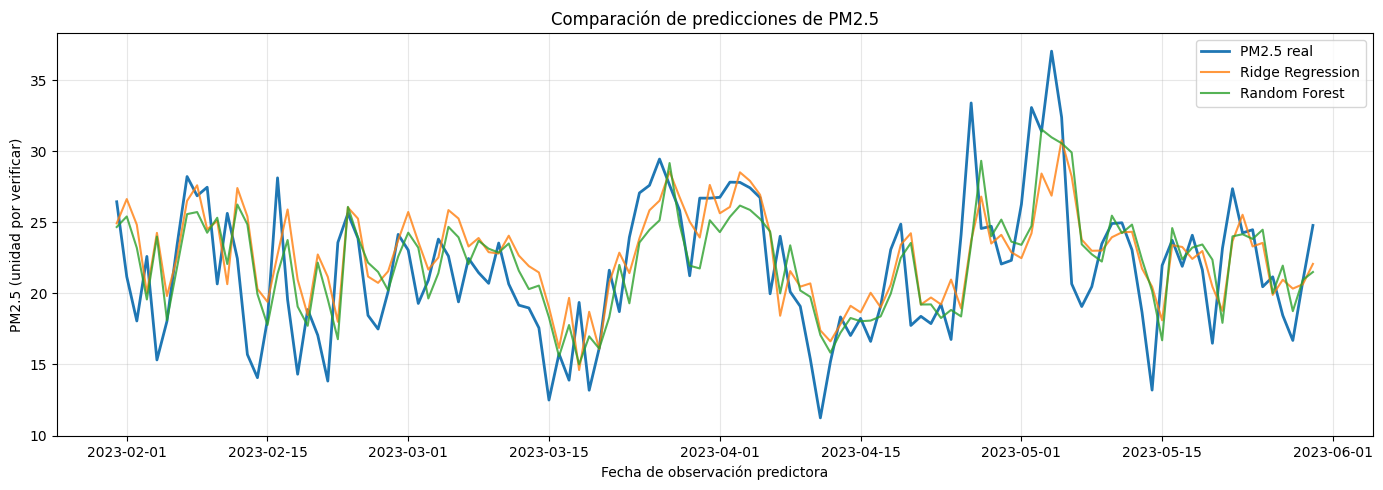


6. ANÁLISIS DE ERRORES


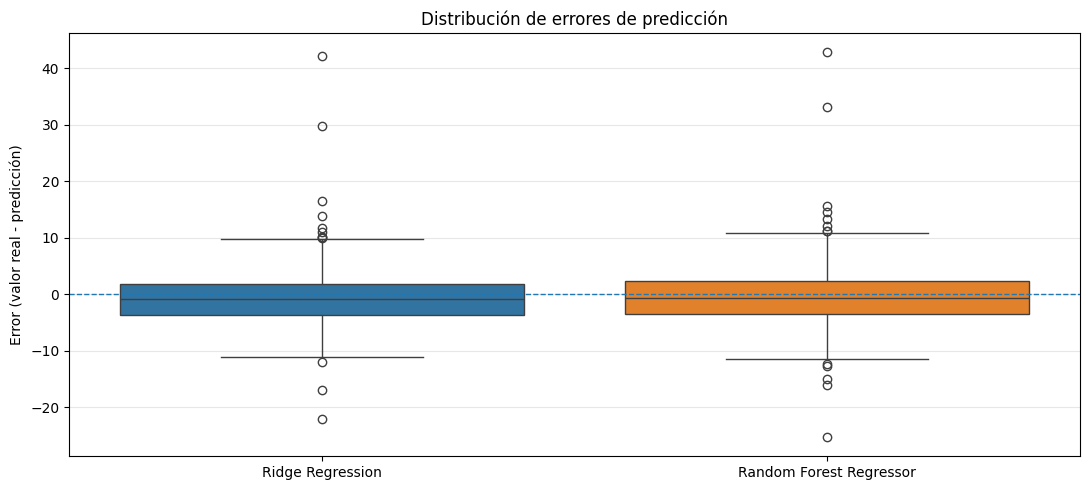


7. EVALUACIÓN EN CONCENTRACIONES ELEVADAS
Umbral percentil 90: 32.568
Registros elevados en prueba: 20


,Modelo,MAE_concentraciones_altas
2,Persistencia,9.9416
1,Random Forest Regressor,10.7245
0,Ridge Regression,10.7461



8. MEJORA FRENTE AL MODELO DE PERSISTENCIA


,Modelo,MAE,RMSE,R2,Mejora_vs_persistencia_pct
0,Ridge Regression,3.6493,4.9894,0.4861,11.8563
1,Random Forest Regressor,3.6743,5.1004,0.4629,11.2520



9. RESUMEN DE LA EVALUACIÓN FINAL
Menor MAE en prueba: Ridge Regression
MAE: 3.6493
RMSE: 4.9894
R2: 0.4861

Evaluación final completada.
Los hiperparámetros no fueron modificados.
Los modelos no fueron reentrenados con datos de prueba.


In [19]:
# TAREA 5
# Actividad 1. Evaluación y comparación de modelos
# Evaluación final de los modelos ajustados

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Verificación del conjunto de prueba
print("=" * 65)
print("1. VERIFICACIÓN DEL CONJUNTO DE PRUEBA")
print("=" * 65)

# Se utilizan los 609 registros reservados.
# Los modelos fueron seleccionados en la Celda 11
# mediante validación cruzada sobre entrenamiento.
X_evaluacion = X_test_script.copy()
y_evaluacion = y_test_script.copy()

assert len(X_evaluacion) == 609
assert len(y_evaluacion) == 609
assert X_evaluacion.shape[1] == 17

assert not X_evaluacion.isna().any().any()
assert not y_evaluacion.isna().any()

print("Registros de prueba:", len(X_evaluacion))
print("Variables predictoras:", X_evaluacion.shape[1])
print("Modelos ajustados:", len(modelos_ajustados))

# Generación de predicciones
print("\n" + "=" * 65)
print("2. GENERACIÓN DE PREDICCIONES")
print("=" * 65)

predicciones = {}

for nombre, modelo in modelos_ajustados.items():

    predicciones[nombre] = modelo.predict(
        X_evaluacion
    )

    print("Predicciones generadas:", nombre)

# Modelo de referencia: persistencia.
# Se utiliza PM2.5 del día actual para estimar
# la concentración del día siguiente.
predicciones["Persistencia"] = (
    X_evaluacion["PM25"].to_numpy()
)

print("Predicciones generadas: Persistencia")

# Cálculo de métricas finales
print("\n" + "=" * 65)
print("3. MÉTRICAS FINALES SOBRE DATOS DE PRUEBA")
print("=" * 65)

resultados_finales = []

for nombre, valores_predichos in predicciones.items():

    mae = mean_absolute_error(
        y_evaluacion,
        valores_predichos
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_evaluacion,
            valores_predichos
        )
    )

    r2 = r2_score(
        y_evaluacion,
        valores_predichos
    )

    resultados_finales.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

df_resultados_finales = (
    pd.DataFrame(resultados_finales)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(df_resultados_finales.round(4))

# Comparación con validación cruzada
print("\n" + "=" * 65)
print("4. COMPARACIÓN VALIDACIÓN VS. PRUEBA")
print("=" * 65)

comparacion_cv_prueba = df_resultados_grid[
    ["Modelo", "MAE_CV", "RMSE_CV", "R2_CV"]
].merge(
    df_resultados_finales,
    on="Modelo",
    how="inner"
)

comparacion_cv_prueba["Diferencia_MAE"] = (
    comparacion_cv_prueba["MAE"]
    - comparacion_cv_prueba["MAE_CV"]
)

display(comparacion_cv_prueba.round(4))

# Visualización de valores reales y predichos
print("\n" + "=" * 65)
print("5. COMPARACIÓN DE PREDICCIONES")
print("=" * 65)

# Recuperar las fechas del conjunto de prueba.
fechas_prueba = (
    df_preparado_script.iloc[
        len(X_train_script):
    ]["fecha"].reset_index(drop=True)
)

# Crear una tabla para analizar las predicciones.
df_predicciones = pd.DataFrame({
    "fecha": fechas_prueba,
    "PM25_real": y_evaluacion.to_numpy(),
    "Ridge": predicciones["Ridge Regression"],
    "Random_Forest": predicciones["Random Forest Regressor"],
    "Persistencia": predicciones["Persistencia"]
})

display(df_predicciones.head(10).round(3))

# Mostrar los últimos 120 días para facilitar
# la lectura de las curvas.

df_grafica = df_predicciones.tail(120)

plt.figure(figsize=(14, 5))

plt.plot(
    df_grafica["fecha"],
    df_grafica["PM25_real"],
    label="PM2.5 real",
    linewidth=2
)

plt.plot(
    df_grafica["fecha"],
    df_grafica["Ridge"],
    label="Ridge Regression",
    alpha=0.8
)

plt.plot(
    df_grafica["fecha"],
    df_grafica["Random_Forest"],
    label="Random Forest",
    alpha=0.8
)

plt.title("Comparación de predicciones de PM2.5")
plt.xlabel("Fecha de observación predictora")
plt.ylabel("PM2.5 (unidad por verificar)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
print("\n")
plt.show()

# Análisis de los errores de predicción
print("\n" + "=" * 65)
print("6. ANÁLISIS DE ERRORES")
print("=" * 65)

errores_modelos = {}

for nombre, valores_predichos in predicciones.items():

    errores_modelos[nombre] = (
        y_evaluacion.to_numpy() - valores_predichos
    )

df_errores = pd.DataFrame(errores_modelos)

plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df_errores[
        ["Ridge Regression", "Random Forest Regressor"]
    ]
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Distribución de errores de predicción")
plt.ylabel("Error (valor real - predicción)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Evaluación de concentraciones elevadas
print("\n" + "=" * 65)
print("7. EVALUACIÓN EN CONCENTRACIONES ELEVADAS")
print("=" * 65)

# Se utiliza el percentil 90 del conjunto de entrenamiento
# como referencia para identificar concentraciones altas.
# El umbral no se calcula utilizando el conjunto de prueba.

umbral_alto = np.percentile(
    y_train_script,
    90
)

mascara_altos = (
    y_evaluacion.to_numpy() >= umbral_alto
)

print("Umbral percentil 90:", round(umbral_alto, 3))
print("Registros elevados en prueba:", mascara_altos.sum())

resultados_altos = []

if mascara_altos.sum() > 0:

    for nombre, valores_predichos in predicciones.items():

        mae_altos = mean_absolute_error(
            y_evaluacion.to_numpy()[mascara_altos],
            valores_predichos[mascara_altos]
        )

        resultados_altos.append({
            "Modelo": nombre,
            "MAE_concentraciones_altas": mae_altos
        })

    df_resultados_altos = pd.DataFrame(
        resultados_altos
    ).sort_values("MAE_concentraciones_altas")

    display(df_resultados_altos.round(4))

else:
    print("No existen registros que superen el umbral.")

# Comparación frente a persistencia
print("\n" + "=" * 65)
print("8. MEJORA FRENTE AL MODELO DE PERSISTENCIA")
print("=" * 65)

mae_persistencia = df_resultados_finales.loc[
    df_resultados_finales["Modelo"] == "Persistencia",
    "MAE"
].iloc[0]

comparacion_persistencia = df_resultados_finales[
    df_resultados_finales["Modelo"] != "Persistencia"
].copy()

comparacion_persistencia["Mejora_vs_persistencia_pct"] = (
    (
        mae_persistencia
        - comparacion_persistencia["MAE"]
    )
    / mae_persistencia
    * 100
)

display(comparacion_persistencia.round(4))

# Resumen final
print("\n" + "=" * 65)
print("9. RESUMEN DE LA EVALUACIÓN FINAL")
print("=" * 65)

mejor_modelo_final = df_resultados_finales.iloc[0]

print("Menor MAE en prueba:", mejor_modelo_final["Modelo"])
print("MAE:", round(mejor_modelo_final["MAE"], 4))
print("RMSE:", round(mejor_modelo_final["RMSE"], 4))
print("R2:", round(mejor_modelo_final["R2"], 4))

print("\nEvaluación final completada.")
print("Los hiperparámetros no fueron modificados.")
print("Los modelos no fueron reentrenados con datos de prueba.")


In [29]:
# TAREA 5
# Actividad 1. Registro y reproducibilidad con MLflow
# Registro y recuperación de modelos en MLFLOW

import json
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from mlflow.tracking import MlflowClient
from mlflow.models import infer_signature

# Configuración y verificación inicial
print("=" * 65)
print("1. CONFIGURACIÓN Y VERIFICACIÓN DE MLFLOW")
print("=" * 65)

mlflow.set_tracking_uri(uri_seguimiento)
mlflow.set_experiment(nombre_experimento)

cliente_final = MlflowClient()

modelos_registro = [
    "Ridge Regression",
    "Random Forest Regressor"
]

nombres_mlflow = {
    "Ridge Regression": "ridge_pm25",
    "Random Forest Regressor": "random_forest_pm25"
}

ids_originales = dict(
    zip(
        df_resultados_grid["Modelo"],
        df_resultados_grid["MLflow_Run_ID"]
    )
)

assert all(
    nombre in modelos_ajustados
    for nombre in modelos_registro
), "Faltan modelos ajustados."

assert all(
    nombre in predicciones
    for nombre in modelos_registro
), "Faltan predicciones originales."

assert len(X_test_script) == 609
assert len(y_test_script) == 609

assert mlflow.active_run() is None, (
    "Existe una ejecución activa en MLflow."
)

print("Experimento:", nombre_experimento)
print("MLflow:", mlflow.__version__)
print("Modelos disponibles:", len(modelos_registro))
print("Registros de prueba:", len(X_test_script))

# Funciones de búsqueda y validación
print("\n" + "=" * 65)
print("2. CONFIGURACIÓN DE FUNCIONES")
print("=" * 65)

# Función que busca un modelo completo en MLflow 3.
# Ignora modelos con estado FAILED o incompletos.
def buscar_modelo_ready(run_id, nombre_modelo):

    experimento = mlflow.get_experiment_by_name(
        nombre_experimento
    )

    if experimento is None:
        return None

    modelos = cliente_final.search_logged_models(
        experiment_ids=[str(experimento.experiment_id)]
    )

    for modelo in modelos:

        if modelo.name != nombre_modelo:
            continue

        if modelo.source_run_id != run_id:
            continue

        if modelo.status != "READY":
            continue

        return f"models:/{modelo.model_id}"

    return None

# Función que recupera el modelo desde MLflow y compara sus
# predicciones con las obtenidas en la Celda 12.
def verificar_predicciones(uri_modelo, nombre):
    modelo_recuperado = mlflow.sklearn.load_model(
        uri_modelo
    )

    pred_originales = np.asarray(
        predicciones[nombre]
    )

    pred_recuperadas = modelo_recuperado.predict(
        X_test_script
    )

    np.testing.assert_allclose(
        pred_originales,
        pred_recuperadas,
        rtol=1e-12,
        atol=1e-12
    )

    return True

# Función que registra métricas finales y archivos de evaluación.
# No realiza un nuevo entrenamiento.
def guardar_evidencias(nombre, run_id):

    fila = df_resultados_finales.loc[
        df_resultados_finales["Modelo"] == nombre
    ].iloc[0]

    mlflow.log_metric(
        "Test_MAE",
        float(fila["MAE"])
    )

    mlflow.log_metric(
        "Test_RMSE",
        float(fila["RMSE"])
    )

    mlflow.log_metric(
        "Test_R2",
        float(fila["R2"])
    )

    mlflow.set_tag("dataset", "RAMA_CDMX")
    mlflow.set_tag(
        "variable_objetivo",
        "PM25_siguiente_dia"
    )
    mlflow.set_tag("registros_prueba", "609")
    mlflow.set_tag("reentrenamiento", "No")

    with tempfile.TemporaryDirectory() as carpeta:

        carpeta = Path(carpeta)

        # Guardar predicciones finales.
        tabla_predicciones = pd.DataFrame({
            "fecha_predictora": (
                df_predicciones["fecha"]
                .dt.strftime("%Y-%m-%d")
            ),
            "PM25_real": y_test_script.to_numpy(),
            "PM25_predicho": predicciones[nombre]
        })

        tabla_predicciones["fecha_objetivo"] = (
            pd.to_datetime(
                tabla_predicciones["fecha_predictora"]
            ) + pd.Timedelta(days=1)
        ).dt.strftime("%Y-%m-%d")

        ruta_predicciones = (
            carpeta / "predicciones_prueba.csv"
        )

        tabla_predicciones.to_csv(
            ruta_predicciones,
            index=False
        )

        mlflow.log_artifact(
            str(ruta_predicciones),
            artifact_path="evaluacion"
        )

        # Guardar resumen del experimento.
        resumen = {
            "modelo": nombre,
            "run_id": run_id,
            "registros_entrenamiento": len(X_train_script),
            "registros_prueba": len(X_test_script),
            "variables_predictoras": list(
                X_test_script.columns
            ),
            "hiperparametros": (
                busquedas_grid[nombre].best_params_
            ),
            "metricas_prueba": {
                "MAE": float(fila["MAE"]),
                "RMSE": float(fila["RMSE"]),
                "R2": float(fila["R2"])
            },
            "semilla": SEMILLA
        }

        ruta_resumen = (
            carpeta / "resumen_modelo.json"
        )

        ruta_resumen.write_text(
            json.dumps(
                resumen,
                indent=4,
                ensure_ascii=False,
                default=str
            ),
            encoding="utf-8"
        )

        mlflow.log_artifact(
            str(ruta_resumen),
            artifact_path="evaluacion"
        )

# Función que registra el modelo entrenado mediante cloudpickle.
# No modifica hiperparámetros ni reentrena.
def registrar_modelo(nombre, nombre_modelo):
    modelo = modelos_ajustados[nombre]

    firma = infer_signature(
        X_test_script,
        modelo.predict(X_test_script)
    )

    resultado = mlflow.sklearn.log_model(
        sk_model=modelo,
        name=nombre_modelo,
        signature=firma,
        input_example=X_test_script.head(3),
        serialization_format="cloudpickle"
    )

    return resultado.model_uri

# Función que busca una recuperación anterior finalizada
# que contenga un modelo con estado READY.
def buscar_recuperacion_previa(run_original, nombre_modelo):
    ejecuciones = mlflow.search_runs(
        experiment_names=[nombre_experimento]
    )

    columna = "tags.run_original"

    if columna not in ejecuciones.columns:
        return None, None

    candidatas = ejecuciones[
        (ejecuciones[columna] == run_original)
        & (ejecuciones["status"] == "FINISHED")
    ]

    for _, fila in candidatas.iterrows():

        run_id = fila["run_id"]

        uri = buscar_modelo_ready(
            run_id,
            nombre_modelo
        )

        if uri is not None:
            return run_id, uri

    return None, None

print("Funciones preparadas correctamente.")

# Registro y recuperación controlada
print("\n" + "=" * 65)
print("3. REGISTRO Y RECUPERACIÓN DE MODELOS")
print("=" * 65)

resultados_registro = []

for nombre in modelos_registro:

    print("\n" + "-" * 65)
    print("Modelo:", nombre)
    print("-" * 65)

    run_original = ids_originales[nombre]
    nombre_modelo = nombres_mlflow[nombre]

    registro_original = cliente_final.get_run(
        run_original
    )

    estado_original = registro_original.info.status

    print("Run original:", run_original)
    print("Estado original:", estado_original)

    run_definitivo = None
    uri_definitiva = None

    # Buscar modelo original completo
    uri_original = buscar_modelo_ready(
        run_original,
        nombre_modelo
    )

    if uri_original is not None:

        verificar_predicciones(
            uri_original,
            nombre
        )

        run_definitivo = run_original
        uri_definitiva = uri_original

        print("Modelo original READY: VERIFICADO")

    # Buscar recuperación previa
    if uri_definitiva is None:

        run_previo, uri_previa = buscar_recuperacion_previa(
            run_original,
            nombre_modelo
        )

        if uri_previa is not None:

            verificar_predicciones(
                uri_previa,
                nombre
            )

            run_definitivo = run_previo
            uri_definitiva = uri_previa

            print(
                "Recuperación anterior reutilizada:",
                run_previo
            )

    # Registro si todavía existe todavía
    if uri_definitiva is None:

        if estado_original == "FAILED":

            # Se conserva la ejecución fallida.
            # Se crea una nueva ejecución de recuperación.

            with mlflow.start_run(
                run_name=(
                    nombre.replace(" ", "_")
                    + "_Recuperacion"
                )
            ) as ejecucion:

                run_definitivo = ejecucion.info.run_id

                mlflow.set_tag(
                    "tipo_ejecucion",
                    "recuperacion_tecnica"
                )

                mlflow.set_tag(
                    "run_original",
                    run_original
                )

                mlflow.set_tag(
                    "motivo_recuperacion",
                    "Error de serializacion"
                )

                # Conservar parámetros y métricas originales.
                mlflow.log_params(
                    registro_original.data.params
                )

                mlflow.log_metrics(
                    registro_original.data.metrics
                )

                guardar_evidencias(
                    nombre,
                    run_definitivo
                )

                uri_definitiva = registrar_modelo(
                    nombre,
                    nombre_modelo
                )

            print(
                "Nueva ejecución de recuperación:",
                run_definitivo
            )

        elif estado_original == "FINISHED":

            # Completar una ejecución que todavía
            # no tenga modelo disponible.

            with mlflow.start_run(
                run_id=run_original
            ):

                guardar_evidencias(
                    nombre,
                    run_original
                )

                uri_definitiva = registrar_modelo(
                    nombre,
                    nombre_modelo
                )

            run_definitivo = run_original

            print("Registro original completado.")

        else:

            raise RuntimeError(
                f"Estado no previsto: {estado_original}"
            )

    # Verificación final del modelo
    assert uri_definitiva is not None

    verificar_predicciones(
        uri_definitiva,
        nombre
    )

    registro_final = cliente_final.get_run(
        run_definitivo
    )

    assert registro_final.info.status == "FINISHED"

    assert all(
        metrica in registro_final.data.metrics
        for metrica in [
            "Test_MAE",
            "Test_RMSE",
            "Test_R2"
        ]
    ), "Faltan métricas finales."

    resultados_registro.append({
        "Modelo": nombre,
        "Run_original": run_original,
        "Run_definitivo": run_definitivo,
        "Estado": registro_final.info.status,
        "Modelo_URI": uri_definitiva
    })

    print("Estado final:", registro_final.info.status)
    print("Modelo URI:", uri_definitiva)
    print("Predicciones reproducidas: CORRECTAS")

# Resumen de modelos registrados
print("\n" + "=" * 65)
print("4. RESUMEN DE MODELOS EN MLFLOW")
print("=" * 65)

df_modelos_registrados = pd.DataFrame(
    resultados_registro
)

display(df_modelos_registrados)

# Verificación final
print("\n" + "=" * 65)
print("5. VERIFICACIÓN FINAL")
print("=" * 65)

assert len(df_modelos_registrados) == 2

assert (
    df_modelos_registrados["Estado"] == "FINISHED"
).all()

assert (
    df_modelos_registrados["Modelo"].nunique() == 2
)

print("Modelos registrados:", len(df_modelos_registrados))
print("Modelos recuperados: 2")
print("Predicciones reproducidas: CORRECTAS")
print("Registro y recuperación: COMPLETADOS")
print("No se realizó ningún reentrenamiento.")


1. CONFIGURACIÓN Y VERIFICACIÓN DE MLFLOW
Experimento: RAMA_PM25_Actividad5
MLflow: 3.17.1
Modelos disponibles: 2
Registros de prueba: 609

2. CONFIGURACIÓN DE FUNCIONES
Funciones preparadas correctamente.

3. REGISTRO Y RECUPERACIÓN DE MODELOS

-----------------------------------------------------------------
Modelo: Ridge Regression
-----------------------------------------------------------------
Run original: 73339b012c7640e6bb99744dc3018c2d
Estado original: FINISHED
Modelo original READY: VERIFICADO
Estado final: FINISHED
Modelo URI: models:/m-c6696e03f8294f8aa3075a56415f6b41
Predicciones reproducidas: CORRECTAS

-----------------------------------------------------------------
Modelo: Random Forest Regressor
-----------------------------------------------------------------
Run original: 764e326660d64a458fc3c3c6ec8f6c3d
Estado original: FAILED
Recuperación anterior reutilizada: 3c164f2beea644eba2f4068cb3b7beb6
Estado final: FINISHED
Modelo URI: models:/m-8de0647dad4c468d8e1308d0f2

,Modelo,Run_original,Run_definitivo,Estado,Modelo_URI
0,Ridge Regression,73339b012c7640e6bb99744dc3018c2d,73339b012c7640e6bb99744dc3018c2d,FINISHED,models:/m-c6696e03f8294f8aa3075a56415f6b41
1,Random Forest Regressor,764e326660d64a458fc3c3c6ec8f6c3d,3c164f2beea644eba2f4068cb3b7beb6,FINISHED,models:/m-8de0647dad4c468d8e1308d0f261f528



5. VERIFICACIÓN FINAL
Modelos registrados: 2
Modelos recuperados: 2
Predicciones reproducidas: CORRECTAS
Registro y recuperación: COMPLETADOS
No se realizó ningún reentrenamiento.


In [31]:
# TAREA 5
# Actividad 1. Registro y reproducibilidad con MLflow
# Verificación final y respaldo de experimentos

import hashlib
import json
import shutil
import sqlite3
import tempfile
import zipfile

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

from mlflow.tracking import MlflowClient
from google.colab import files

# Verificación de modelos registrados
print("=" * 65)
print("1. VERIFICACIÓN FINAL DE MODELOS")
print("=" * 65)

mlflow.set_tracking_uri(uri_seguimiento)

cliente_verificacion = MlflowClient()

modelos_verificados = []

for _, fila in df_modelos_registrados.iterrows():

    nombre = fila["Modelo"]
    uri_modelo = fila["Modelo_URI"]
    run_id = fila["Run_definitivo"]

    modelo_recuperado = mlflow.sklearn.load_model(
        uri_modelo
    )

    pred_recuperadas = modelo_recuperado.predict(
        X_test_script
    )

    pred_originales = np.asarray(
        predicciones[nombre]
    )

    np.testing.assert_allclose(
        pred_originales,
        pred_recuperadas,
        rtol=1e-12,
        atol=1e-12
    )

    registro = cliente_verificacion.get_run(
        run_id
    )

    assert registro.info.status == "FINISHED"

    modelos_verificados.append({
        "Modelo": nombre,
        "Run_ID": run_id,
        "Estado": registro.info.status,
        "Predicciones": "COINCIDEN",
        "Modelo_URI": uri_modelo
    })

    print(nombre, ": RECUPERADO CORRECTAMENTE")

df_verificacion_final = pd.DataFrame(
    modelos_verificados
)

display(df_verificacion_final)

# Verificación de métricas y artefactos
print("\n" + "=" * 65)
print("2. VERIFICACIÓN DE MÉTRICAS Y ARTEFACTOS")
print("=" * 65)

for _, fila in df_modelos_registrados.iterrows():

    nombre = fila["Modelo"]
    run_id = fila["Run_definitivo"]

    registro = cliente_verificacion.get_run(
        run_id
    )

    metricas = registro.data.metrics

    for metrica in [
        "CV_MAE",
        "CV_RMSE",
        "CV_R2",
        "Test_MAE",
        "Test_RMSE",
        "Test_R2"
    ]:

        assert metrica in metricas, (
            f"Falta la métrica {metrica} en {nombre}"
        )

    # Verificar archivos convencionales de evaluación.
    artefactos = cliente_verificacion.list_artifacts(
        run_id,
        path="evaluacion"
    )

    rutas = [archivo.path for archivo in artefactos]

    assert "evaluacion/predicciones_prueba.csv" in rutas, (
        f"Faltan predicciones de {nombre}"
    )

    assert "evaluacion/resumen_modelo.json" in rutas, (
        f"Falta el resumen de {nombre}"
    )

    print(nombre)
    print("Métricas: CORRECTAS")
    print("Artefactos: CORRECTOS")

# Verificación de integridad del Dataset
print("\n" + "=" * 65)
print("3. VERIFICACIÓN DE INTEGRIDAD DEL DATASET")
print("=" * 65)

ruta_dataset = Path("/content/datos_limp.csv")

assert ruta_dataset.exists(), (
    "No se encontró datos_limp.csv en /content."
)

hash_dataset_actual = hashlib.sha256(
    ruta_dataset.read_bytes()
).hexdigest()

hash_dataset_esperado = (
    "93c76aa30597174fce7bbd49092aafdd586bd56786415091bb3e79177dab1d8b"
)

assert hash_dataset_actual == hash_dataset_esperado, (
    "La huella SHA-256 del dataset no coincide."
)

print("Archivo:", ruta_dataset.name)
print("SHA-256:", hash_dataset_actual)
print("Integridad del dataset: VERIFICADA")

# Preparación del respaldo de MLFLOW
print("\n" + "=" * 65)
print("4. PREPARACIÓN DEL RESPALDO DE MLFLOW")
print("=" * 65)

directorio_origen = Path("/content/mlflow_rama")

ruta_db_origen = directorio_origen / "mlflow.db"

assert ruta_db_origen.exists(), (
    "No se encontró la base de datos MLflow."
)

# Crear una carpeta temporal para preparar el respaldo.
directorio_respaldo = Path(
    tempfile.mkdtemp(prefix="respaldo_mlflow_")
)

# Realizar una copia consistente de SQLite.
ruta_db_respaldo = directorio_respaldo / "mlflow.db"

conexion_origen = sqlite3.connect(
    str(ruta_db_origen)
)

conexion_destino = sqlite3.connect(
    str(ruta_db_respaldo)
)

conexion_origen.backup(conexion_destino)

conexion_destino.close()
conexion_origen.close()

print("Base de datos respaldada correctamente.")

# Copia de artefactos y modelos
print("\n" + "=" * 65)
print("5. COPIA DE ARTEFACTOS Y MODELOS")
print("=" * 65)

# MLflow 3 puede utilizar varias carpetas locales.
# Se conserva la estructura completa del directorio
# de seguimiento, excluyendo la base activa y auxiliares.

for elemento in directorio_origen.iterdir():

    if elemento.name in [
        "mlflow.db",
        "mlflow.db-wal",
        "mlflow.db-shm",
        "mlflow_respaldo.db"
    ]:
        continue

    destino = directorio_respaldo / elemento.name

    if elemento.is_dir():

        shutil.copytree(
            elemento,
            destino,
            dirs_exist_ok=True
        )

    elif elemento.is_file():

        shutil.copy2(
            elemento,
            destino
        )

# Comprobar los directorios respaldados.
print("Elementos incluidos:")

for elemento in directorio_respaldo.iterdir():
    print("-", elemento.name)

# Creación de manifiesto de reproducibilidad
print("\n" + "=" * 65)
print("6. MANIFIESTO DE REPRODUCIBILIDAD")
print("=" * 65)

manifiesto = {
    "proyecto": "Prediccion PM2.5 CDMX",
    "experimento": nombre_experimento,
    "fecha_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "mlflow_version": mlflow.__version__,
    "registros_entrenamiento": len(X_train_script),
    "registros_prueba": len(X_test_script),
    "variables_predictoras": len(variables_script),
    "dataset_sha256": hash_dataset_actual,
    "modelos": df_modelos_registrados.to_dict(
        orient="records"
    )
}

ruta_manifiesto = (
    directorio_respaldo / "manifiesto.json"
)

ruta_manifiesto.write_text(
    json.dumps(
        manifiesto,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("Manifiesto generado correctamente.")

# Generación y verificación del archivo ZIP
print("\n" + "=" * 65)
print("7. GENERACIÓN DEL RESPALDO ZIP")
print("=" * 65)

ruta_zip = Path("/content/mlflow_rama_final.zip")

with zipfile.ZipFile(
    ruta_zip,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archivo_zip:

    for archivo in directorio_respaldo.rglob("*"):

        if archivo.is_file():

            archivo_zip.write(
                archivo,
                arcname=archivo.relative_to(
                    directorio_respaldo
                )
            )

with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:

    archivo_incorrecto = archivo_zip.testzip()

    assert archivo_incorrecto is None, (
        "El ZIP contiene un archivo dañado."
    )

    archivos_zip = archivo_zip.namelist()

    assert "mlflow.db" in archivos_zip
    assert "manifiesto.json" in archivos_zip

print("Archivo generado:", ruta_zip.name)
print("Tamaño:", ruta_zip.stat().st_size, "bytes")
print("Archivos incluidos:", len(archivos_zip))
print("Integridad del ZIP: VERIFICADA")

# Descarga del respaldo final
print("\n" + "=" * 65)
print("8. DESCARGA DEL RESPALDO FINAL")
print("=" * 65)

files.download(str(ruta_zip))

print("\nRespaldo final generado y descarga solicitada.")
print("Los modelos no fueron reentrenados.")
print("Notebook técnico finalizado.")


1. VERIFICACIÓN FINAL DE MODELOS
Ridge Regression : RECUPERADO CORRECTAMENTE
Random Forest Regressor : RECUPERADO CORRECTAMENTE


,Modelo,Run_ID,Estado,Predicciones,Modelo_URI
0,Ridge Regression,73339b012c7640e6bb99744dc3018c2d,FINISHED,COINCIDEN,models:/m-c6696e03f8294f8aa3075a56415f6b41
1,Random Forest Regressor,3c164f2beea644eba2f4068cb3b7beb6,FINISHED,COINCIDEN,models:/m-8de0647dad4c468d8e1308d0f261f528



2. VERIFICACIÓN DE MÉTRICAS Y ARTEFACTOS
Ridge Regression
Métricas: CORRECTAS
Artefactos: CORRECTOS
Random Forest Regressor
Métricas: CORRECTAS
Artefactos: CORRECTOS

3. VERIFICACIÓN DE INTEGRIDAD DEL DATASET
Archivo: datos_limp.csv
SHA-256: 93c76aa30597174fce7bbd49092aafdd586bd56786415091bb3e79177dab1d8b
Integridad del dataset: VERIFICADA

4. PREPARACIÓN DEL RESPALDO DE MLFLOW
Base de datos respaldada correctamente.

5. COPIA DE ARTEFACTOS Y MODELOS
Elementos incluidos:
- artefactos
- mlflow.db

6. MANIFIESTO DE REPRODUCIBILIDAD
Manifiesto generado correctamente.

7. GENERACIÓN DEL RESPALDO ZIP
Archivo generado: mlflow_rama_final.zip
Tamaño: 1766871 bytes
Archivos incluidos: 27
Integridad del ZIP: VERIFICADA

8. DESCARGA DEL RESPALDO FINAL


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Respaldo final generado y descarga solicitada.
Los modelos no fueron reentrenados.
Notebook técnico finalizado.
